In [1]:
# Block 1: Load and prepare the semi-synthetic LAOS observations

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


DATA_DIR = Path(".")

METADATA_PATH = DATA_DIR / "metadata.json"

if not METADATA_PATH.is_file():
    METADATA_PATH = DATA_DIR / "metadata(1).json"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Benchmark metadata not found in: {DATA_DIR.resolve()}"
    )

with METADATA_PATH.open("r", encoding="utf-8") as file:
    benchmark_metadata = json.load(file)

expected_name = "APR18-based semi-synthetic LAOS change benchmark v2"

if benchmark_metadata.get("name") != expected_name:
    raise ValueError("Unexpected benchmark metadata.")

OBSERVED_DIR = DATA_DIR / "observable"

if not OBSERVED_DIR.is_dir():
    OBSERVED_DIR = DATA_DIR

case_files = {
    "control": "control.csv",
    "change_10pct": "change_10pct.csv",
    "change_20pct": "change_20pct.csv",
    "change_30pct": "change_30pct.csv",
}

if not (OBSERVED_DIR / "control.csv").is_file():
    case_files["control"] = "control(2).csv"

CASE_LABELS = {
    "control": "Control",
    "change_10pct": "Change 10%",
    "change_20pct": "Change 20%",
    "change_30pct": "Change 30%",
}

CASE_COLORS = {
    "control": "#333333",
    "change_10pct": "#0072B2",
    "change_20pct": "#E69F00",
    "change_30pct": "#CC79A7",
}

SAMPLING_HZ = 50.0
OMEGA_RAD_S = 1.0
FUNDAMENTAL_HZ = OMEGA_RAD_S / (2.0 * np.pi)
PERIOD_S = 1.0 / FUNDAMENTAL_HZ

required_columns = [
    "time_s",
    "strain",
    "shear_rate_1_s",
    "stress_Pa",
]

expected_rows = int(benchmark_metadata["sampling"]["rows"])
expected_bounds_s = [
    float(benchmark_metadata["sampling"]["start_s"]),
    float(benchmark_metadata["sampling"]["end_s"]),
]

laos_records = {}

for case_name, filename in case_files.items():
    file_path = OBSERVED_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Observation file not found: {file_path}")

    data = pd.read_csv(file_path)

    if not set(required_columns).issubset(data.columns):
        raise ValueError(f"Unexpected columns in {filename}")

    data = data[required_columns].apply(
        pd.to_numeric,
        errors="raise",
    )

    if not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(f"Missing or nonfinite values in {filename}")

    times_s = data["time_s"].to_numpy()

    if len(data) != expected_rows or np.any(np.diff(times_s) <= 0):
        raise ValueError(f"Unexpected row count or timestamps in {filename}")

    if not np.allclose(
        times_s[[0, -1]],
        expected_bounds_s,
        rtol=0.0,
        atol=1e-8,
    ):
        raise ValueError(f"Unexpected time range in {filename}")

    laos_records[case_name] = {
        "data": data.reset_index(drop=True),
        "fundamental_hz": FUNDAMENTAL_HZ,
        "period_s": PERIOD_S,
    }

control_data = laos_records["control"]["data"]
input_columns = ["time_s", "strain", "shear_rate_1_s"]
control_inputs = control_data[input_columns].to_numpy()

original_times_s = control_data["time_s"].to_numpy()

first_grid_index = int(np.ceil(original_times_s[0] * SAMPLING_HZ))
last_grid_index = int(np.floor(original_times_s[-1] * SAMPLING_HZ))

uniform_times_s = (
    np.arange(first_grid_index, last_grid_index + 1)
    / SAMPLING_HZ
)

laos_prepared_records = {}
preparation_rows = []

for case_name, record in laos_records.items():
    data = record["data"]

    if not np.array_equal(
        data[input_columns].to_numpy(),
        control_inputs,
    ):
        raise ValueError(f"Input mismatch in {case_name}")

    prepared_data = pd.DataFrame({"time_s": uniform_times_s})

    for column in required_columns[1:]:
        prepared_data[column] = np.interp(
            uniform_times_s,
            data["time_s"].to_numpy(),
            data[column].to_numpy(),
        )

    laos_prepared_records[case_name] = {
        "data": prepared_data,
        "sampling_hz": SAMPLING_HZ,
        "fundamental_hz": FUNDAMENTAL_HZ,
        "period_s": PERIOD_S,
    }

    preparation_rows.append({
        "case": case_name,
        "original_n_samples": len(data),
        "uniform_n_samples": len(prepared_data),
        "first_time_s": uniform_times_s[0],
        "last_time_s": uniform_times_s[-1],
        "sampling_hz": SAMPLING_HZ,
        "fundamental_hz": FUNDAMENTAL_HZ,
        "period_s": PERIOD_S,
    })

stft_data_summary = pd.DataFrame(preparation_rows)

print("Benchmark:", benchmark_metadata["name"])
print("Observation directory:", OBSERVED_DIR.resolve())

display(stft_data_summary.round(5))

print("\nPreparation matches the FFT notebook:")
print("Common 50 Hz time grid, linear interpolation, and no extrapolation.")
print("No additional startup removal or amplitude normalization.")
print("Truth files have not been loaded.")
print("No reference interval, alarm threshold, or detected time is set yet.")

/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Benchmark: APR18-based semi-synthetic LAOS change benchmark v2
Observation directory: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/observable


,case,original_n_samples,uniform_n_samples,first_time_s,last_time_s,sampling_hz,fundamental_hz,period_s
0,control,1995,1997,0.06,39.98,50.0,0.15915,6.28319
1,change_10pct,1995,1997,0.06,39.98,50.0,0.15915,6.28319
2,change_20pct,1995,1997,0.06,39.98,50.0,0.15915,6.28319
3,change_30pct,1995,1997,0.06,39.98,50.0,0.15915,6.28319



Preparation matches the FFT notebook:
Common 50 Hz time grid, linear interpolation, and no extrapolation.
No additional startup removal or amplitude normalization.
Truth files have not been loaded.
No reference interval, alarm threshold, or detected time is set yet.


In [2]:
# Block 2: Configure STFT windows, timing, and frequency band

WINDOW_CYCLES = 2.0
REQUESTED_HOP_S = 0.5

N_WINDOW = int(
    round(WINDOW_CYCLES * PERIOD_S * SAMPLING_HZ)
)
N_HOP = int(round(REQUESTED_HOP_S * SAMPLING_HZ))

if N_WINDOW < 4 or N_WINDOW > len(uniform_times_s):
    raise ValueError("Invalid window length.")

if N_HOP < 1 or N_HOP > N_WINDOW:
    raise ValueError("Invalid hop length.")

WINDOW_DURATION_S = N_WINDOW / SAMPLING_HZ
HOP_DURATION_S = N_HOP / SAMPLING_HZ
FREQUENCY_BIN_SPACING_HZ = SAMPLING_HZ / N_WINDOW

SPECTRAL_BAND_HZ = (
    0.5 * FUNDAMENTAL_HZ,
    8.0 * FUNDAMENTAL_HZ,
)

sample_indices = np.arange(N_WINDOW)

STFT_WINDOW = (
    0.5
    - 0.5 * np.cos(2.0 * np.pi * sample_indices / N_WINDOW)
)

STFT_FREQUENCIES_HZ = np.fft.rfftfreq(
    N_WINDOW,
    d=1.0 / SAMPLING_HZ,
)

STFT_BAND_MASK = (
    (STFT_FREQUENCIES_HZ >= SPECTRAL_BAND_HZ[0])
    & (STFT_FREQUENCIES_HZ <= SPECTRAL_BAND_HZ[1])
)

if np.count_nonzero(STFT_BAND_MASK) < 2:
    raise ValueError("The selected spectral band contains too few bins.")

FEATURE_COLUMNS = [
    "I1_Pa",
    "I3_Pa",
    "I5_Pa",
    "I3_I1",
    "I5_I1",
    "spectral_power_Pa2",
    "spectral_entropy",
    "spectral_bandwidth_Hz",
]

FEATURE_LABELS = {
    "I1_Pa": ("I1", "Amplitude (Pa)"),
    "I3_Pa": ("I3", "Amplitude (Pa)"),
    "I5_Pa": ("I5", "Amplitude (Pa)"),
    "I3_I1": ("I3/I1", "Amplitude ratio"),
    "I5_I1": ("I5/I1", "Amplitude ratio"),
    "spectral_power_Pa2": ("Spectral power", "Power (Pa²)"),
    "spectral_entropy": ("Spectral entropy", "Normalized entropy"),
    "spectral_bandwidth_Hz": ("Spectral bandwidth", "Bandwidth (Hz)"),
}

window_start_indices = np.arange(
    0,
    len(uniform_times_s) - N_WINDOW + 1,
    N_HOP,
)

window_start_times_s = uniform_times_s[window_start_indices]
window_end_times_s = window_start_times_s + WINDOW_DURATION_S

window_schedule = pd.DataFrame({
    "start_index": window_start_indices,
    "stop_index_exclusive": window_start_indices + N_WINDOW,
    "window_start_s": window_start_times_s,
    "window_center_s": (
        window_start_times_s + WINDOW_DURATION_S / 2.0
    ),
    "window_end_s": window_end_times_s,
})

stft_settings = {
    "sampling_hz": SAMPLING_HZ,
    "fundamental_hz": FUNDAMENTAL_HZ,
    "requested_window_cycles": WINDOW_CYCLES,
    "actual_window_cycles": WINDOW_DURATION_S / PERIOD_S,
    "n_window": N_WINDOW,
    "n_hop": N_HOP,
    "window_duration_s": WINDOW_DURATION_S,
    "hop_duration_s": HOP_DURATION_S,
    "overlap_percent": 100.0 * (1.0 - N_HOP / N_WINDOW),
    "frequency_bin_spacing_hz": FREQUENCY_BIN_SPACING_HZ,
    "spectral_band_low_hz": SPECTRAL_BAND_HZ[0],
    "spectral_band_high_hz": SPECTRAL_BAND_HZ[1],
    "spectral_band_n_bins": int(np.count_nonzero(STFT_BAND_MASK)),
    "n_windows": len(window_schedule),
    "window": "periodic Hann",
    "padding": False,
    "feature_timestamp": "exclusive window end",
}

print("STFT settings:")
display(pd.DataFrame([stft_settings]).T.rename(columns={0: "value"}))

print("\nFirst windows:")
display(window_schedule.head().round(5))

print("\nLast windows:")
display(window_schedule.tail().round(5))

print("\nOnly complete windows are used.")
print("Feature and alarm times will use the exclusive window end.")
print("Window centers are retained for interpretation.")
print("No reference interval or alarm threshold has been selected.")

STFT settings:


,value
sampling_hz,50.0
fundamental_hz,0.159155
requested_window_cycles,2.0
actual_window_cycles,1.998986
n_window,628
n_hop,25
window_duration_s,12.56
hop_duration_s,0.5
overlap_percent,96.019108
frequency_bin_spacing_hz,0.079618



First windows:


,start_index,stop_index_exclusive,window_start_s,window_center_s,window_end_s
0,0,628,0.06,6.34,12.62
1,25,653,0.56,6.84,13.12
2,50,678,1.06,7.34,13.62
3,75,703,1.56,7.84,14.12
4,100,728,2.06,8.34,14.62



Last windows:


,start_index,stop_index_exclusive,window_start_s,window_center_s,window_end_s
50,1250,1878,25.06,31.34,37.62
51,1275,1903,25.56,31.84,38.12
52,1300,1928,26.06,32.34,38.62
53,1325,1953,26.56,32.84,39.12
54,1350,1978,27.06,33.34,39.62



Only complete windows are used.
Feature and alarm times will use the exclusive window end.
Window centers are retained for interpretation.
No reference interval or alarm threshold has been selected.


In [3]:
# Block 3: Define window features and check numerical calculations

def estimate_target_harmonics(
    signal_values,
    sampling_hz,
    fundamental_hz,
):
    values = np.asarray(signal_values, dtype=float)

    if values.ndim != 1 or len(values) < 4:
        raise ValueError("Invalid signal shape or length.")

    if not np.isfinite(values).all():
        raise ValueError("The signal contains nonfinite values.")

    if (
        sampling_hz <= 0
        or fundamental_hz <= 0
        or 5 * fundamental_hz >= sampling_hz / 2
    ):
        raise ValueError("Invalid sampling or harmonic frequencies.")

    n_samples = len(values)
    indices = np.arange(n_samples)
    relative_times_s = indices / sampling_hz

    window = (
        0.5
        - 0.5 * np.cos(2.0 * np.pi * indices / n_samples)
    )

    centered_values = values - np.mean(values)

    amplitudes = []

    for harmonic in [1, 3, 5]:
        coefficient = np.sum(
            window
            * centered_values
            * np.exp(
                -2j
                * np.pi
                * harmonic
                * fundamental_hz
                * relative_times_s
            )
        )

        amplitudes.append(
            2.0 * np.abs(coefficient) / np.sum(window)
        )

    return np.asarray(amplitudes, dtype=float)


def extract_window_features(
    signal_values,
    sampling_hz,
    fundamental_hz,
    spectral_band_hz,
):
    values = np.asarray(signal_values, dtype=float)

    I1, I3, I5 = estimate_target_harmonics(
        values,
        sampling_hz,
        fundamental_hz,
    )

    n_samples = len(values)
    indices = np.arange(n_samples)

    window = (
        0.5
        - 0.5 * np.cos(2.0 * np.pi * indices / n_samples)
    )

    centered_values = values - np.mean(values)
    windowed_values = centered_values * window

    fft_values = np.fft.rfft(windowed_values)
    frequencies_hz = np.fft.rfftfreq(
        n_samples,
        d=1.0 / sampling_hz,
    )

    # One-sided PSD, with units of Pa²/Hz for stress input.
    psd = (
        np.abs(fft_values) ** 2
        / (sampling_hz * np.sum(window ** 2))
    )

    if n_samples % 2 == 0:
        psd[1:-1] *= 2.0
    else:
        psd[1:] *= 2.0

    frequency_spacing_hz = sampling_hz / n_samples
    bin_power = psd * frequency_spacing_hz

    band_mask = (
        (frequencies_hz >= spectral_band_hz[0])
        & (frequencies_hz <= spectral_band_hz[1])
    )

    if np.count_nonzero(band_mask) < 2:
        raise ValueError("The spectral band contains too few bins.")

    band_frequencies_hz = frequencies_hz[band_mask]
    band_power = bin_power[band_mask]
    spectral_power = float(np.sum(band_power))

    if spectral_power > 0:
        probabilities = band_power / spectral_power
        positive_mask = probabilities > 0

        entropy = (
            -np.sum(
                probabilities[positive_mask]
                * np.log(probabilities[positive_mask])
            )
            / np.log(len(probabilities))
        )

        centroid_hz = np.sum(
            probabilities * band_frequencies_hz
        )

        bandwidth_hz = np.sqrt(
            np.sum(
                probabilities
                * (band_frequencies_hz - centroid_hz) ** 2
            )
        )
    else:
        entropy = np.nan
        bandwidth_hz = np.nan

    # Parseval check uses the full spectrum, not only the selected band.
    full_spectrum_power = float(np.sum(bin_power))

    weighted_time_power = float(
        np.sum(windowed_values ** 2) / np.sum(window ** 2)
    )

    parseval_error = (
        abs(full_spectrum_power - weighted_time_power)
        / max(weighted_time_power, np.finfo(float).tiny)
    )

    # This checks numerical validity, not measurement reliability.
    valid_fundamental = bool(I1 > np.finfo(float).eps)

    return {
        "I1_Pa": float(I1),
        "I3_Pa": float(I3),
        "I5_Pa": float(I5),
        "I3_I1": float(I3 / I1) if valid_fundamental else np.nan,
        "I5_I1": float(I5 / I1) if valid_fundamental else np.nan,
        "spectral_power_Pa2": spectral_power,
        "spectral_entropy": float(entropy),
        "spectral_bandwidth_Hz": float(bandwidth_hz),
        "valid_fundamental": valid_fundamental,
        "parseval_relative_error": float(parseval_error),
    }


# Check the estimator using a stationary signal with known amplitudes.
calibration_times_s = np.arange(N_WINDOW) / SAMPLING_HZ
known_amplitudes = np.array([0.2, 0.02, 0.007])

calibration_signal = (
    0.05
    + known_amplitudes[0]
    * np.sin(2 * np.pi * FUNDAMENTAL_HZ * calibration_times_s + 0.3)
    + known_amplitudes[1]
    * np.sin(2 * np.pi * 3 * FUNDAMENTAL_HZ * calibration_times_s - 0.4)
    + known_amplitudes[2]
    * np.sin(2 * np.pi * 5 * FUNDAMENTAL_HZ * calibration_times_s + 0.8)
)

estimated_amplitudes = estimate_target_harmonics(
    calibration_signal,
    SAMPLING_HZ,
    FUNDAMENTAL_HZ,
)

calibration_summary = pd.DataFrame({
    "harmonic": ["I1", "I3", "I5"],
    "known_amplitude_Pa": known_amplitudes,
    "estimated_amplitude_Pa": estimated_amplitudes,
    "relative_error_percent": (
        100.0
        * (estimated_amplitudes - known_amplitudes)
        / known_amplitudes
    ),
})

calibration_features = extract_window_features(
    calibration_signal,
    SAMPLING_HZ,
    FUNDAMENTAL_HZ,
    SPECTRAL_BAND_HZ,
)

print("Stationary-signal amplitude check:")
display(calibration_summary.round(8))

print("\nExample window features and numerical diagnostics:")
display(
    pd.DataFrame([calibration_features]).T.rename(columns={0: "value"})
)

if calibration_features["parseval_relative_error"] > 1e-10:
    raise ValueError("The PSD normalization failed the Parseval check.")

print("\nFeature functions are ready.")
print("The calibration checks numerical calculations on a stationary signal.")
print("It does not validate change detection or performance on real blood.")

Stationary-signal amplitude check:


,harmonic,known_amplitude_Pa,estimated_amplitude_Pa,relative_error_percent
0,I1,0.200,0.199995,-0.002608
1,I3,0.020,0.020004,0.017873
2,I5,0.007,0.007001,0.018609



Example window features and numerical diagnostics:


,value
I1_Pa,0.199995
I3_Pa,0.020004
I5_Pa,0.007001
I3_I1,0.10002
I5_I1,0.035007
spectral_power_Pa2,0.020225
spectral_entropy,0.344323
spectral_bandwidth_Hz,0.059923
valid_fundamental,True
parseval_relative_error,0.0



Feature functions are ready.
The calibration checks numerical calculations on a stationary signal.
It does not validate change detection or performance on real blood.


In [4]:
# Block 4: Extract time-resolved features from all four cases

stft_feature_tables = {}
feature_check_rows = []

time_columns = [
    "window_start_s",
    "window_center_s",
    "window_end_s",
]

for case_name, record in laos_prepared_records.items():
    stress_values = record["data"]["stress_Pa"].to_numpy()
    feature_rows = []

    for window in window_schedule.itertuples(index=False):
        start_index = int(window.start_index)
        stop_index = int(window.stop_index_exclusive)

        signal_segment = stress_values[start_index:stop_index]

        if len(signal_segment) != N_WINDOW:
            raise ValueError(f"Incomplete window in {case_name}")

        features = extract_window_features(
            signal_segment,
            SAMPLING_HZ,
            FUNDAMENTAL_HZ,
            SPECTRAL_BAND_HZ,
        )

        feature_rows.append({
            "window_start_s": float(window.window_start_s),
            "window_center_s": float(window.window_center_s),
            "window_end_s": float(window.window_end_s),
            **features,
        })

    feature_table = pd.DataFrame(feature_rows)

    if len(feature_table) != len(window_schedule):
        raise ValueError(f"Unexpected feature-table length in {case_name}")

    feature_values = feature_table[FEATURE_COLUMNS].to_numpy(dtype=float)

    if not np.isfinite(feature_values).all():
        raise ValueError(f"Nonfinite feature values in {case_name}")

    if not feature_table["valid_fundamental"].all():
        raise ValueError(f"Invalid fundamental amplitude in {case_name}")

    max_parseval_error = float(
        feature_table["parseval_relative_error"].max()
    )

    if max_parseval_error > 1e-10:
        raise ValueError(f"PSD normalization check failed in {case_name}")

    entropy_values = feature_table["spectral_entropy"].to_numpy()

    if np.any(entropy_values < -1e-12) or np.any(
        entropy_values > 1.0 + 1e-12
    ):
        raise ValueError(f"Invalid spectral entropy in {case_name}")

    stft_feature_tables[case_name] = feature_table

    feature_check_rows.append({
        "case": case_name,
        "n_windows": len(feature_table),
        "n_features": len(FEATURE_COLUMNS),
        "first_feature_time_s": feature_table["window_end_s"].iloc[0],
        "last_feature_time_s": feature_table["window_end_s"].iloc[-1],
        "all_features_finite": bool(np.isfinite(feature_values).all()),
        "all_fundamentals_valid": bool(
            feature_table["valid_fundamental"].all()
        ),
        "max_parseval_relative_error": max_parseval_error,
    })

stft_feature_checks = pd.DataFrame(feature_check_rows)

stft_feature_long_table = pd.concat(
    [
        table.assign(case=case_name)
        for case_name, table in stft_feature_tables.items()
    ],
    ignore_index=True,
)

stft_feature_long_table = stft_feature_long_table[
    ["case"]
    + time_columns
    + FEATURE_COLUMNS
    + ["valid_fundamental", "parseval_relative_error"]
]

print("Feature extraction checks:")
display(stft_feature_checks)

print("\nFirst control feature rows:")
display(
    stft_feature_tables["control"][
        time_columns + FEATURE_COLUMNS
    ].head().round(7)
)

print("\nLast Change 30% feature rows:")
display(
    stft_feature_tables["change_30pct"][
        time_columns + FEATURE_COLUMNS
    ].tail().round(7)
)

print(
    f"\nTotal extracted windows: {len(stft_feature_long_table)}"
)
print("Each case contains eight features at 55 window-end times.")
print("Diagnostic columns are not additional detection features.")
print("No baseline normalization or alarm rule has been applied.")

Feature extraction checks:


,case,n_windows,n_features,first_feature_time_s,last_feature_time_s,all_features_finite,all_fundamentals_valid,max_parseval_relative_error
0,control,55,8,12.62,39.62,True,True,6.008723e-16
1,change_10pct,55,8,12.62,39.62,True,True,5.769864e-16
2,change_20pct,55,8,12.62,39.62,True,True,5.704680e-16
3,change_30pct,55,8,12.62,39.62,True,True,5.825941e-16



First control feature rows:


,window_start_s,window_center_s,window_end_s,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
0,0.06,6.34,12.62,0.190602,0.019295,0.006832,0.101231,0.035845,0.018416,0.346189,0.062027
1,0.56,6.84,13.12,0.190355,0.019165,0.006801,0.100682,0.035729,0.018329,0.345417,0.061883
2,1.06,7.34,13.62,0.190105,0.019068,0.006769,0.100305,0.035608,0.018282,0.345335,0.061806
3,1.56,7.84,14.12,0.189861,0.018991,0.006752,0.100028,0.035565,0.018227,0.345073,0.061725
4,2.06,8.34,14.62,0.189635,0.018929,0.006744,0.099816,0.035561,0.018173,0.344791,0.061650



Last Change 30% feature rows:


,window_start_s,window_center_s,window_end_s,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,spectral_power_Pa2,spectral_entropy,spectral_bandwidth_Hz
50,25.06,31.34,37.62,0.240779,0.023241,0.008378,0.096526,0.034796,0.029318,0.344131,0.061084
51,25.56,31.84,38.12,0.240754,0.023207,0.008381,0.096393,0.034809,0.029308,0.344028,0.061069
52,26.06,32.34,38.62,0.240718,0.023184,0.008377,0.096313,0.034801,0.029294,0.343924,0.061054
53,26.56,32.84,39.12,0.240677,0.023162,0.008378,0.096238,0.034811,0.029278,0.343813,0.061039
54,27.06,33.34,39.62,0.240638,0.023143,0.008375,0.096175,0.034803,0.029265,0.343758,0.061031



Total extracted windows: 220
Each case contains eight features at 55 window-end times.
Diagnostic columns are not additional detection features.
No baseline normalization or alarm rule has been applied.


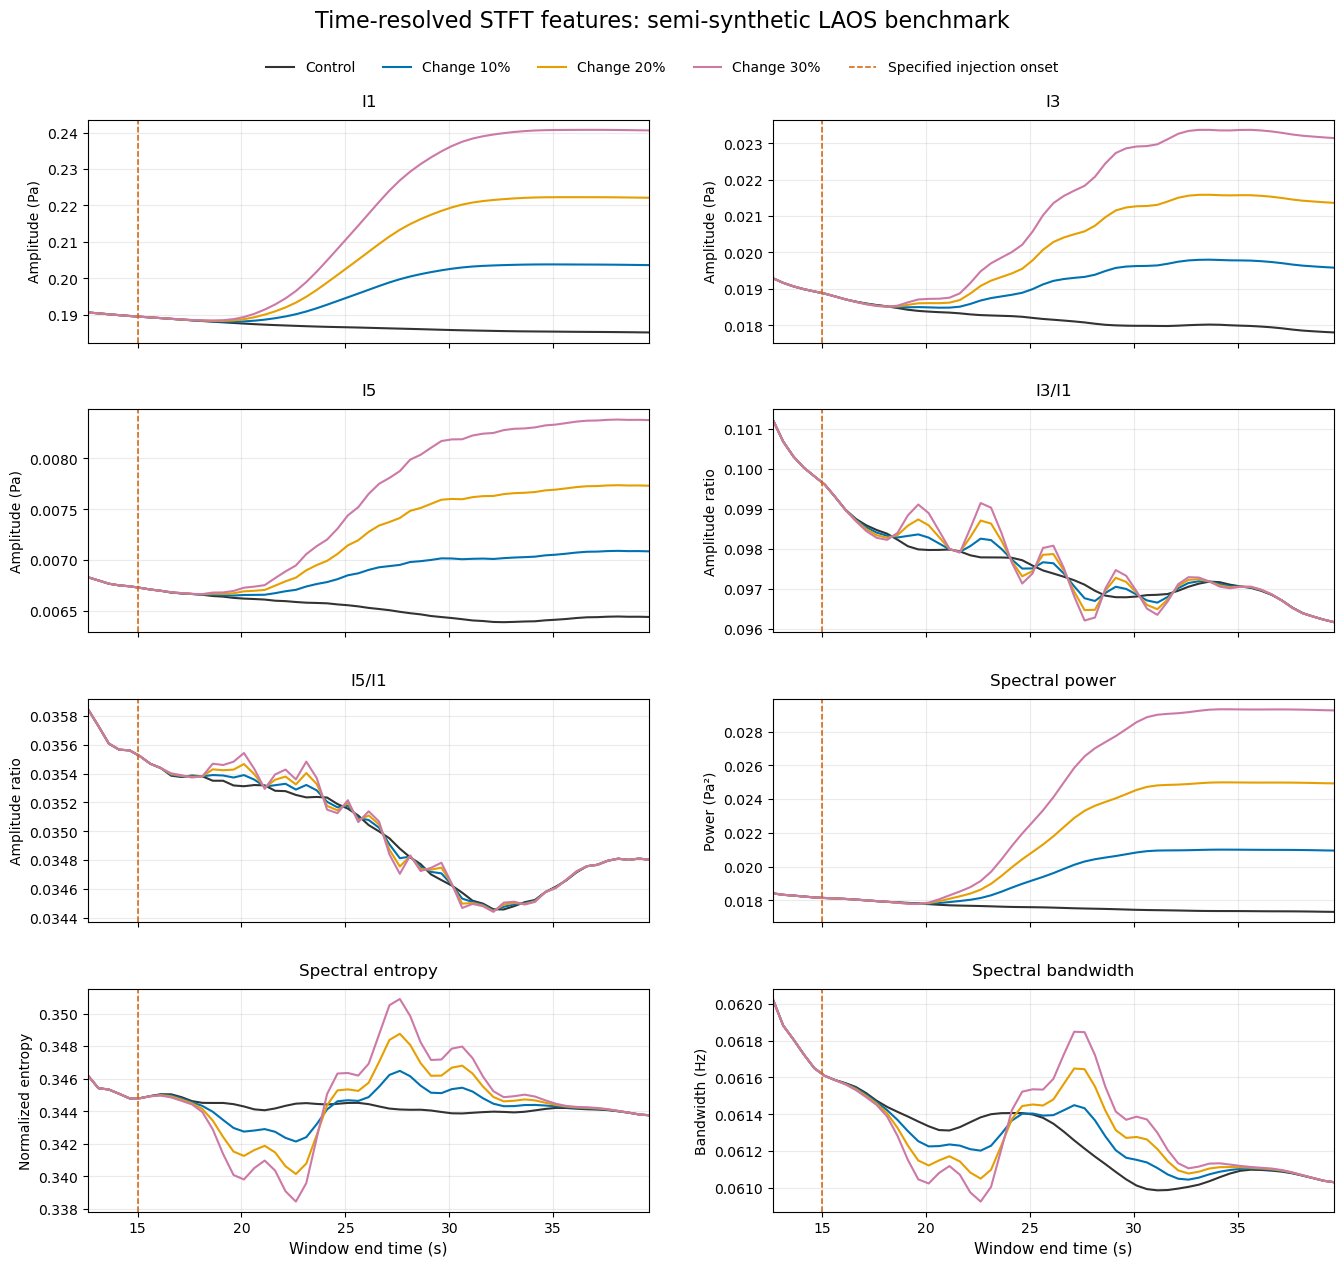

All curves use window-end timestamps.
The dashed line marks the specified injection onset.
Each feature value summarizes a 12.56 s window.
Subplots use separate vertical scales.
No candidate change time has been estimated.


In [6]:
# Block 5: Plot the eight time-resolved features

DESIGN_ONSET_S = float(
    benchmark_metadata["construction"]["onset_s"]
)

fig, axes = plt.subplots(
    4,
    2,
    figsize=(14, 13),
    sharex=True,
    constrained_layout=False,
)

for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    title, ylabel = FEATURE_LABELS[feature]

    for case_name, feature_table in stft_feature_tables.items():
        ax.plot(
            feature_table["window_end_s"],
            feature_table[feature],
            color=CASE_COLORS[case_name],
            linewidth=1.5,
            label=CASE_LABELS[case_name],
        )

    ax.axvline(
        DESIGN_ONSET_S,
        color="#D55E00",
        linestyle="--",
        linewidth=1.1,
        label="Specified injection onset",
    )

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(alpha=0.25)

    ax.set_xlim(
        window_schedule["window_end_s"].iloc[0],
        window_schedule["window_end_s"].iloc[-1],
    )

    ax.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False,
    )

for ax in axes[-1, :]:
    ax.set_xlabel("Window end time (s)", fontsize=11)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.suptitle(
    "Time-resolved STFT features: semi-synthetic LAOS benchmark",
    fontsize=16,
    y=0.985,
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=5,
    fontsize=10,
    frameon=False,
)

fig.subplots_adjust(
    top=0.90,
    bottom=0.06,
    left=0.09,
    right=0.98,
    hspace=0.30,
    wspace=0.22,
)

stft_feature_figure = fig
plt.show()

print("All curves use window-end timestamps.")
print("The dashed line marks the specified injection onset.")
print("Each feature value summarizes a 12.56 s window.")
print("Subplots use separate vertical scales.")
print("No candidate change time has been estimated.")

Late-window median differences relative to control (%):


,Change 10%,Change 20%,Change 30%
I1,9.99924,19.99847,29.99771
I3,10.00006,20.00012,30.00018
I5,9.99985,19.99970,29.99954
I3/I1,0.00058,0.00107,0.00148
I5/I1,0.00029,0.00053,0.00073
Spectral power,20.99915,43.99814,68.99697
Spectral entropy,0.00074,0.00136,0.00188
Spectral bandwidth,0.00044,0.00080,0.00111



Peak paired responses:


,case,feature,peak_signed_difference_percent,peak_response_window_end_s,n_late_windows
0,change_10pct,I1_Pa,9.99958,39.62,3
1,change_10pct,I3_Pa,10.00022,39.62,3
2,change_10pct,I5_Pa,9.99990,39.62,3
3,change_10pct,I3_I1,0.47746,22.62,3
4,change_10pct,I5_I1,0.24459,23.12,3
5,change_10pct,spectral_power_Pa2,21.00340,37.12,3
6,change_10pct,spectral_entropy,0.68858,27.62,3
7,change_10pct,spectral_bandwidth_Hz,0.35871,27.62,3
8,change_20pct,I1_Pa,19.99915,39.62,3
9,change_20pct,I3_Pa,20.00044,39.62,3


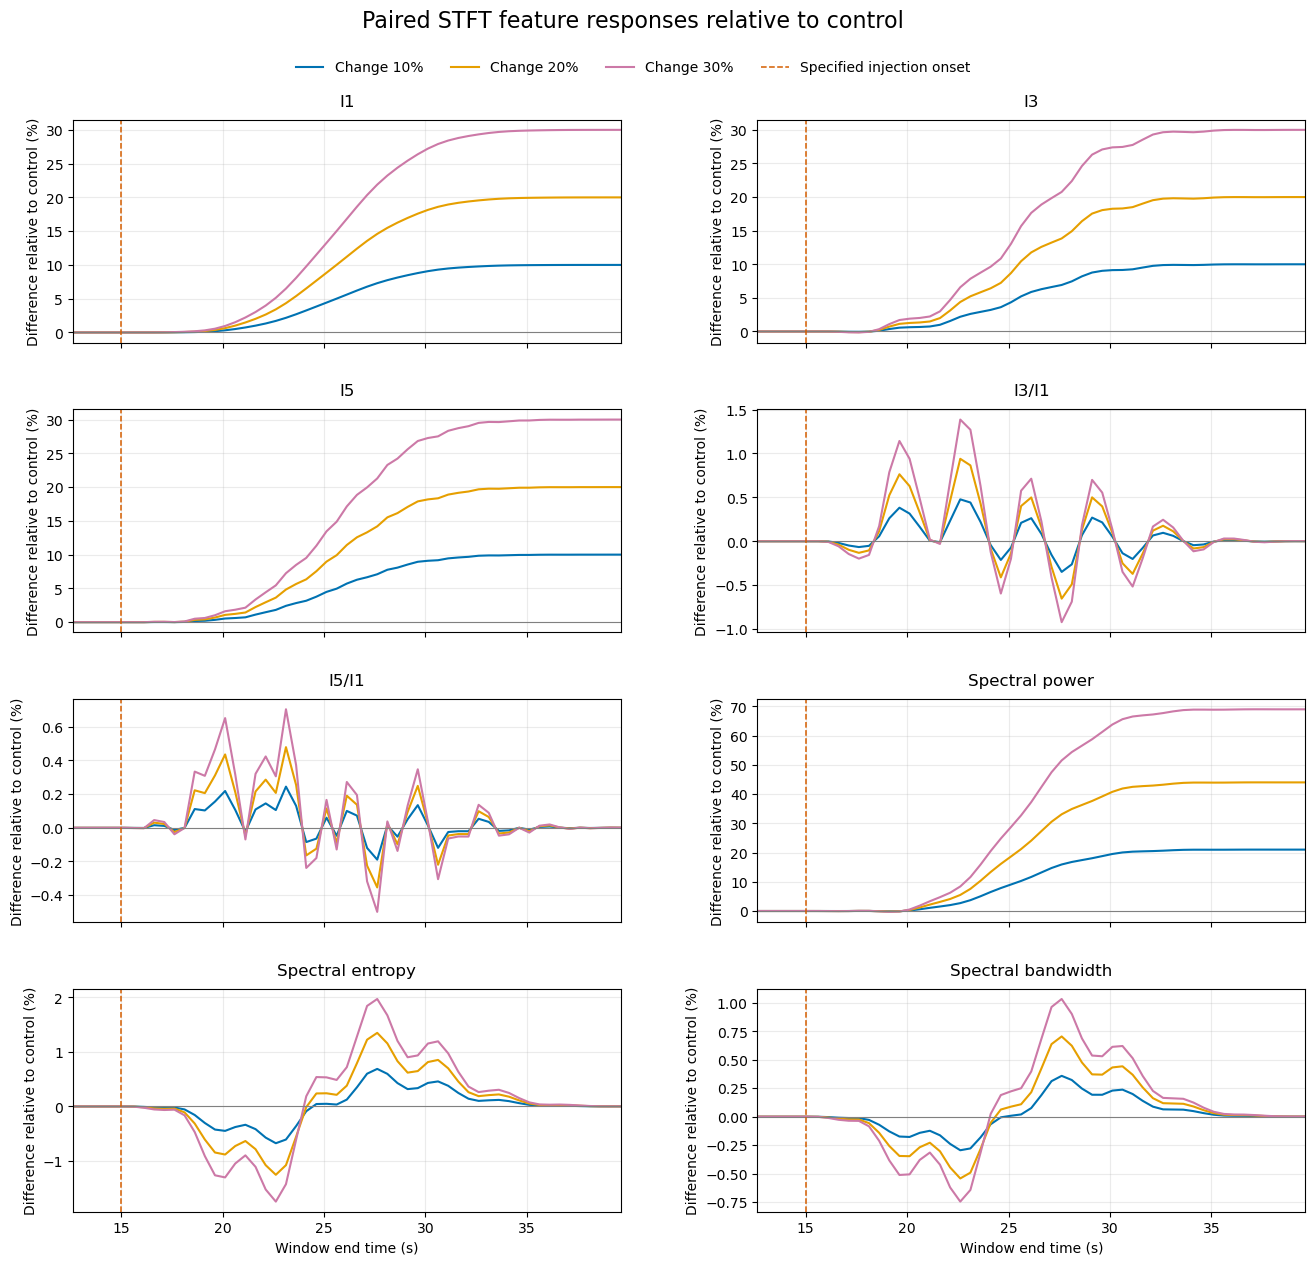


Paired differences are benchmark diagnostics, not alarm scores.
Peak response times are not detected onset times.
Late summaries use three highly overlapping windows per case.


In [7]:
# Block 6: Quantify paired feature differences relative to control

control_features = stft_feature_tables["control"]
control_times = control_features[time_columns].to_numpy()

stft_paired_feature_tables = {}
response_rows = []

# Use windows starting at or after 26 s for late-response summaries.
LATE_WINDOW_START_S = 26.0

for case_name, feature_table in stft_feature_tables.items():
    if case_name == "control":
        continue

    if not np.array_equal(
        feature_table[time_columns].to_numpy(),
        control_times,
    ):
        raise ValueError(f"Window-time mismatch in {case_name}")

    paired_table = feature_table[time_columns].copy()

    post_onset_mask = (
        feature_table["window_end_s"].to_numpy() > DESIGN_ONSET_S
    )

    late_mask = (
        feature_table["window_start_s"].to_numpy()
        >= LATE_WINDOW_START_S
    )

    if not late_mask.any():
        raise ValueError("No windows are available for the late summary.")

    for feature in FEATURE_COLUMNS:
        reference = control_features[feature].to_numpy(dtype=float)
        observed = feature_table[feature].to_numpy(dtype=float)

        difference = observed - reference

        difference_percent = np.divide(
            100.0 * difference,
            reference,
            out=np.full_like(difference, np.nan),
            where=np.abs(reference) > np.finfo(float).eps,
        )

        if not np.isfinite(difference_percent).all():
            raise ValueError(
                f"Undefined paired percentage for {case_name}, {feature}"
            )

        paired_table[f"{feature}_difference"] = difference
        paired_table[f"{feature}_difference_percent"] = difference_percent

        post_indices = np.flatnonzero(post_onset_mask)

        peak_index = post_indices[
            np.argmax(np.abs(difference_percent[post_onset_mask]))
        ]

        response_rows.append({
            "case": case_name,
            "feature": feature,
            "peak_signed_difference_percent": (
                difference_percent[peak_index]
            ),
            "peak_abs_difference_percent": (
                abs(difference_percent[peak_index])
            ),
            "peak_response_window_end_s": (
                feature_table["window_end_s"].iloc[peak_index]
            ),
            "late_median_difference_percent": (
                np.median(difference_percent[late_mask])
            ),
            "n_late_windows": int(np.count_nonzero(late_mask)),
        })

    stft_paired_feature_tables[case_name] = paired_table

stft_response_summary = pd.DataFrame(response_rows)

late_response_table = (
    stft_response_summary.pivot(
        index="feature",
        columns="case",
        values="late_median_difference_percent",
    )
    .reindex(FEATURE_COLUMNS)
    .reindex(
        columns=["change_10pct", "change_20pct", "change_30pct"]
    )
)

late_response_table.index = [
    FEATURE_LABELS[feature][0]
    for feature in late_response_table.index
]

late_response_table.columns = [
    CASE_LABELS[case] for case in late_response_table.columns
]

print("Late-window median differences relative to control (%):")
display(late_response_table.round(5))

print("\nPeak paired responses:")
display(
    stft_response_summary[
        [
            "case",
            "feature",
            "peak_signed_difference_percent",
            "peak_response_window_end_s",
            "n_late_windows",
        ]
    ].round(5)
)

fig, axes = plt.subplots(
    4,
    2,
    figsize=(14, 13),
    sharex=True,
    constrained_layout=False,
)

for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    for case_name, paired_table in stft_paired_feature_tables.items():
        ax.plot(
            paired_table["window_end_s"],
            paired_table[f"{feature}_difference_percent"],
            color=CASE_COLORS[case_name],
            linewidth=1.5,
            label=CASE_LABELS[case_name],
        )

    ax.axhline(0, color="gray", linewidth=0.8)

    ax.axvline(
        DESIGN_ONSET_S,
        color="#D55E00",
        linestyle="--",
        linewidth=1.1,
        label="Specified injection onset",
    )

    ax.set_title(FEATURE_LABELS[feature][0], pad=10)
    ax.set_ylabel("Difference relative to control (%)")
    ax.grid(alpha=0.25)

    ax.set_xlim(
        window_schedule["window_end_s"].iloc[0],
        window_schedule["window_end_s"].iloc[-1],
    )

    ax.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False,
    )

for ax in axes[-1, :]:
    ax.set_xlabel("Window end time (s)")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.suptitle(
    "Paired STFT feature responses relative to control",
    fontsize=16,
    y=0.985,
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=4,
    frameon=False,
)

fig.subplots_adjust(
    top=0.90,
    bottom=0.06,
    left=0.10,
    right=0.98,
    hspace=0.30,
    wspace=0.25,
)

stft_paired_feature_figure = fig
plt.show()

print("\nPaired differences are benchmark diagnostics, not alarm scores.")
print("Peak response times are not detected onset times.")
print("Late summaries use three highly overlapping windows per case.")

In [8]:
# Block 7: Establish a control reference and compute robust scores

REFERENCE_CASE = "control"
Z_THRESHOLD = 5.0
PERSISTENCE_S = 1.0
ALARM_DIRECTION = "two-sided"

reference_table = stft_feature_tables[REFERENCE_CASE]

reference_rows = []

for feature in FEATURE_COLUMNS:
    values = reference_table[feature].to_numpy(dtype=float)

    if not np.all(np.isfinite(values)):
        raise ValueError(f"Non-finite reference values: {feature}")

    reference_median = float(np.median(values))
    reference_mad = float(
        np.median(np.abs(values - reference_median))
    )
    reference_scale = 1.4826 * reference_mad

    if not np.isfinite(reference_scale) or reference_scale <= 0:
        raise ValueError(
            f"A positive reference scale is required for {feature}. "
            "Review the reference data before scoring."
        )

    reference_rows.append({
        "feature": feature,
        "reference_median": reference_median,
        "reference_MAD": reference_mad,
        "reference_scale": reference_scale,
        "n_reference_windows": len(values),
    })

stft_reference_summary = (
    pd.DataFrame(reference_rows)
    .set_index("feature")
    .loc[FEATURE_COLUMNS]
)

stft_score_tables = {}

time_columns = [
    "window_start_s",
    "window_center_s",
    "window_end_s",
]

for case, feature_table in stft_feature_tables.items():
    score_table = feature_table[time_columns].copy()

    for feature in FEATURE_COLUMNS:
        reference_median = stft_reference_summary.loc[
            feature, "reference_median"
        ]
        reference_scale = stft_reference_summary.loc[
            feature, "reference_scale"
        ]

        score_table[f"{feature}_z"] = (
            feature_table[feature].to_numpy(dtype=float)
            - reference_median
        ) / reference_scale

    stft_score_tables[case] = score_table

stft_alarm_config = {
    "reference_case": REFERENCE_CASE,
    "reference_scope": "full control record",
    "reference_mode": "offline matched-control benchmark",
    "reference_n_windows": int(len(reference_table)),
    "reference_first_window_end_s": float(
        reference_table["window_end_s"].iloc[0]
    ),
    "reference_last_window_end_s": float(
        reference_table["window_end_s"].iloc[-1]
    ),
    "location_estimator": "median",
    "scale_estimator": "1.4826 * MAD",
    "z_threshold": Z_THRESHOLD,
    "direction": ALARM_DIRECTION,
    "persistence_s": PERSISTENCE_S,
    "timestamp": "exclusive window end",
    "monitoring_scope": "all available feature windows",
}

control_score_summary = pd.DataFrame([
    {
        "feature": feature,
        "max_abs_control_z": float(
            stft_score_tables[REFERENCE_CASE][f"{feature}_z"]
            .abs()
            .max()
        ),
        "n_control_windows_at_or_above_threshold": int(
            (
                stft_score_tables[REFERENCE_CASE][f"{feature}_z"]
                .abs() >= Z_THRESHOLD
            ).sum()
        ),
    }
    for feature in FEATURE_COLUMNS
])

print("Frozen control-reference statistics:")
display(stft_reference_summary)

print("\nAlarm configuration:")
print(json.dumps(stft_alarm_config, indent=2))

print("\nIn-sample control score diagnostics:")
display(control_score_summary)

print(
    "\nReference statistics use the full control record. "
    "This is an offline benchmark calibration."
)
print(
    "Control score diagnostics reuse the calibration data "
    "and do not establish an independent false-alarm rate."
)
print(
    "Scores have been computed, but alarm times "
    "have not yet been assigned."
)

Frozen control-reference statistics:


,reference_median,reference_MAD,reference_scale,n_reference_windows
feature,,,,
I1_Pa,0.186385,0.001005,0.001490,55
I3_Pa,0.018152,0.000172,0.000256,55
I5_Pa,0.006531,0.000098,0.000146,55
I3_I1,0.097387,0.000553,0.000820,55
I5_I1,0.035043,0.000307,0.000456,55
spectral_power_Pa2,0.017569,0.000203,0.000301,55
spectral_entropy,0.344203,0.000248,0.000367,55
spectral_bandwidth_Hz,0.061312,0.000219,0.000325,55



Alarm configuration:
{
  "reference_case": "control",
  "reference_scope": "full control record",
  "reference_mode": "offline matched-control benchmark",
  "reference_n_windows": 55,
  "reference_first_window_end_s": 12.620000000000001,
  "reference_last_window_end_s": 39.62,
  "location_estimator": "median",
  "scale_estimator": "1.4826 * MAD",
  "z_threshold": 5.0,
  "direction": "two-sided",
  "persistence_s": 1.0,
  "timestamp": "exclusive window end",
  "monitoring_scope": "all available feature windows"
}

In-sample control score diagnostics:


,feature,max_abs_control_z,n_control_windows_at_or_above_threshold
0,I1_Pa,2.829966,0
1,I3_Pa,4.472481,0
2,I5_Pa,2.063788,0
3,I3_I1,4.689313,0
4,I5_I1,1.760686,0
5,spectral_power_Pa2,2.815579,0
6,spectral_entropy,5.405753,1
7,spectral_bandwidth_Hz,2.201958,0



Reference statistics use the full control record. This is an offline benchmark calibration.
Control score diagnostics reuse the calibration data and do not establish an independent false-alarm rate.
Scores have been computed, but alarm times have not yet been assigned.


In [17]:
# Block 8: Detect sustained same-direction alarms without ground truth

def detect_sustained_alarm(
    times_s,
    z_scores,
    threshold,
    persistence_s,
    expected_hop_s,
):
    times_s = np.asarray(times_s, dtype=float)
    z_scores = np.asarray(z_scores, dtype=float)

    if times_s.shape != z_scores.shape or times_s.ndim != 1:
        raise ValueError(
            "Times and scores must be matching 1D arrays."
        )

    if (
        len(times_s) < 1
        or not np.all(np.isfinite(times_s))
        or np.any(np.diff(times_s) <= 0)
    ):
        raise ValueError(
            "Times must be finite, non-empty, and strictly increasing."
        )

    parameters = np.asarray(
        [threshold, persistence_s, expected_hop_s],
        dtype=float,
    )

    if (
        not np.all(np.isfinite(parameters))
        or threshold <= 0
        or persistence_s < 0
        or expected_hop_s <= 0
    ):
        raise ValueError("Invalid alarm parameters.")

    above_threshold = (
        np.isfinite(z_scores)
        & (np.abs(z_scores) >= threshold)
    )

    crossing_indices = np.flatnonzero(above_threshold)

    result = {
        "first_crossing_s": (
            float(times_s[crossing_indices[0]])
            if len(crossing_indices)
            else np.nan
        ),
        "confirmed_run_start_s": np.nan,
        "confirmation_time_s": np.nan,
        "confirmation_z": np.nan,
        "confirmation_direction": "none",
        "n_windows_at_or_above_threshold": int(
            above_threshold.sum()
        ),
        "confirmed": False,
    }

    run_start_index = None
    last_run_index = None
    run_direction = 0

    for index in range(len(times_s)):
        if not above_threshold[index]:
            run_start_index = None
            last_run_index = None
            run_direction = 0
            continue

        direction = int(np.sign(z_scores[index]))

        continues_run = (
            run_start_index is not None
            and direction == run_direction
            and index == last_run_index + 1
            and np.isclose(
                times_s[index] - times_s[last_run_index],
                expected_hop_s,
                rtol=0,
                atol=1e-8,
            )
        )

        if not continues_run:
            run_start_index = index
            run_direction = direction

        last_run_index = index

        elapsed_s = (
            times_s[index] - times_s[run_start_index]
        )

        if elapsed_s >= persistence_s - 1e-9:
            result.update({
                "confirmed_run_start_s": float(
                    times_s[run_start_index]
                ),
                "confirmation_time_s": float(times_s[index]),
                "confirmation_z": float(z_scores[index]),
                "confirmation_direction": (
                    "increase"
                    if run_direction > 0
                    else "decrease"
                ),
                "confirmed": True,
            })
            break

    return result


# Record the revised alarm rule for downstream exports.
stft_alarm_config.update({
    "threshold_comparison": "abs(signed_z) >= z_threshold",
    "same_direction_required_during_persistence": True,
    "nonfinite_scores_break_runs": True,
    "consecutive_output_requirement": (
        "Adjacent outputs separated by the expected hop duration"
    ),
})


# Evaluate the first confirmed alarm for each case and feature.
alarm_rows = []

for case, score_table in stft_score_tables.items():
    times_s = score_table[
        "window_end_s"
    ].to_numpy(dtype=float)

    for feature in FEATURE_COLUMNS:
        alarm_result = detect_sustained_alarm(
            times_s=times_s,
            z_scores=score_table[
                f"{feature}_z"
            ].to_numpy(dtype=float),
            threshold=Z_THRESHOLD,
            persistence_s=PERSISTENCE_S,
            expected_hop_s=HOP_DURATION_S,
        )

        alarm_rows.append({
            "case": case,
            "feature": feature,
            **alarm_result,
        })

stft_alarm_summary = pd.DataFrame(alarm_rows)

print("Per-feature alarm results:")
display(stft_alarm_summary)


# Present confirmed alarm times in a feature-by-case table.
stft_confirmation_table = (
    stft_alarm_summary.pivot(
        index="feature",
        columns="case",
        values="confirmation_time_s",
    )
    .reindex(
        index=FEATURE_COLUMNS,
        columns=list(stft_score_tables),
    )
)

stft_confirmation_table.index = [
    FEATURE_LABELS[feature][0]
    for feature in stft_confirmation_table.index
]

stft_confirmation_table.columns = [
    CASE_LABELS[case]
    for case in stft_confirmation_table.columns
]

print(
    "\nConfirmed alarm times, using window-end timestamps (s):"
)
display(stft_confirmation_table)


# Inspect alarms on the control used for reference calibration.
print("\nControl alarm diagnostics:")
display(
    stft_alarm_summary.loc[
        stft_alarm_summary["case"] == "control",
        [
            "feature",
            "first_crossing_s",
            "confirmed_run_start_s",
            "confirmation_time_s",
            "confirmation_direction",
            "n_windows_at_or_above_threshold",
            "confirmed",
        ],
    ]
)

print(
    "\nNaN confirmation times mean no confirmed alarm "
    "within the available record."
)
print(
    "Persistence requires consecutive same-direction "
    "threshold exceedances across at least the specified duration."
)
print(
    "Nonfinite scores, direction changes, below-threshold "
    "outputs, and time gaps interrupt a run."
)
print(
    "First crossings may precede the run that eventually "
    "satisfies the persistence requirement."
)
print(
    "Confirmation times are alarm availability times. "
    "Run starts are retrospective timestamps."
)
print(
    "Overlapping outputs are not independent confirmations."
)
print(
    "Control diagnostics reuse the reference calibration record."
)
print(
    "No ground-truth onset was used in alarm detection."
)

Per-feature alarm results:


,case,feature,first_crossing_s,confirmed_run_start_s,confirmation_time_s,confirmation_z,confirmation_direction,n_windows_at_or_above_threshold,confirmed
0,control,I1_Pa,NaN,NaN,NaN,NaN,none,0,False
1,control,I3_Pa,NaN,NaN,NaN,NaN,none,0,False
2,control,I5_Pa,NaN,NaN,NaN,NaN,none,0,False
3,control,I3_I1,NaN,NaN,NaN,NaN,none,0,False
4,control,I5_I1,NaN,NaN,NaN,NaN,none,0,False
5,control,spectral_power_Pa2,NaN,NaN,NaN,NaN,none,0,False
6,control,spectral_entropy,12.62,NaN,NaN,NaN,none,1,False
7,control,spectral_bandwidth_Hz,NaN,NaN,NaN,NaN,none,0,False
8,change_10pct,I1_Pa,25.12,25.12,26.12,7.012693,increase,30,True
9,change_10pct,I3_Pa,28.62,28.62,29.62,5.717296,increase,23,True



Confirmed alarm times, using window-end timestamps (s):


,Control,Change 10%,Change 20%,Change 30%
I1,NaN,26.12,24.12,23.12
I3,NaN,29.62,25.62,23.62
I5,NaN,NaN,27.12,25.62
I3/I1,NaN,NaN,NaN,NaN
I5/I1,NaN,NaN,NaN,NaN
Spectral power,NaN,26.12,24.62,23.62
Spectral entropy,NaN,28.12,20.62,20.12
Spectral bandwidth,NaN,NaN,NaN,NaN



Control alarm diagnostics:


,feature,first_crossing_s,confirmed_run_start_s,confirmation_time_s,confirmation_direction,n_windows_at_or_above_threshold,confirmed
0,I1_Pa,NaN,NaN,NaN,none,0,False
1,I3_Pa,NaN,NaN,NaN,none,0,False
2,I5_Pa,NaN,NaN,NaN,none,0,False
3,I3_I1,NaN,NaN,NaN,none,0,False
4,I5_I1,NaN,NaN,NaN,none,0,False
5,spectral_power_Pa2,NaN,NaN,NaN,none,0,False
6,spectral_entropy,12.62,NaN,NaN,none,1,False
7,spectral_bandwidth_Hz,NaN,NaN,NaN,none,0,False



NaN confirmation times mean no confirmed alarm within the available record.
Persistence requires consecutive same-direction threshold exceedances across at least the specified duration.
Nonfinite scores, direction changes, below-threshold outputs, and time gaps interrupt a run.
First crossings may precede the run that eventually satisfies the persistence requirement.
Confirmation times are alarm availability times. Run starts are retrospective timestamps.
Overlapping outputs are not independent confirmations.
Control diagnostics reuse the reference calibration record.
No ground-truth onset was used in alarm detection.


In [18]:
# Block 9: Evaluate frozen alarm results against injection ground truth

TRUTH_DIR = DATA_DIR / "truth"

ground_truth_onsets = {}

for case in stft_score_tables:
    if case == "control":
        continue

    truth_path = TRUTH_DIR / f"{case}_truth.csv"

    if not truth_path.exists():
        raise FileNotFoundError(
            f"Ground-truth file not found: {truth_path.resolve()}"
        )

    truth_table = pd.read_csv(truth_path)

    required_truth_columns = [
        "time_s",
        "ground_truth_onset_s",
    ]

    missing_columns = [
        column for column in required_truth_columns
        if column not in truth_table.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing truth columns for {case}: {missing_columns}"
        )

    truth_times = truth_table["time_s"].to_numpy(dtype=float)
    observed_times = laos_records[case]["data"][
        "time_s"
    ].to_numpy(dtype=float)

    if (
        truth_times.shape != observed_times.shape
        or not np.allclose(
            truth_times, observed_times, rtol=0, atol=1e-9
        )
    ):
        raise ValueError(f"Truth time alignment failed: {case}")

    onset_values = truth_table[
        "ground_truth_onset_s"
    ].to_numpy(dtype=float)

    if not np.all(np.isfinite(onset_values)):
        raise ValueError(f"Invalid onset values: {case}")

    if not np.allclose(
        onset_values, onset_values[0], rtol=0, atol=1e-9
    ):
        raise ValueError(f"Inconsistent onset values: {case}")

    ground_truth_onsets[case] = float(onset_values[0])


evaluation_rows = []

for row in stft_alarm_summary.to_dict("records"):
    case = row["case"]
    confirmation_time = row["confirmation_time_s"]
    confirmed = bool(row["confirmed"])

    onset_s = ground_truth_onsets.get(case, np.nan)
    delay_s = np.nan

    if case == "control":
        status = (
            "control confirmed alarm"
            if confirmed else "control no confirmed alarm"
        )
    elif not confirmed:
        status = "no confirmed alarm within record"
    elif confirmation_time < onset_s - 1e-9:
        status = "pre-injection confirmed alarm"
    else:
        status = "post-injection confirmed alarm"
        delay_s = float(confirmation_time - onset_s)

    evaluation_rows.append({
        **row,
        "ground_truth_onset_s": onset_s,
        "evaluation_status": status,
        "detection_delay_s": delay_s,
    })

stft_alarm_evaluation = pd.DataFrame(evaluation_rows)

print("Per-feature evaluation:")
display(
    stft_alarm_evaluation[
        [
            "case",
            "feature",
            "ground_truth_onset_s",
            "confirmed_run_start_s",
            "confirmation_time_s",
            "confirmation_direction",
            "evaluation_status",
            "detection_delay_s",
        ]
    ]
)

change_cases = list(ground_truth_onsets)

stft_delay_table = (
    stft_alarm_evaluation[
        stft_alarm_evaluation["case"].isin(change_cases)
    ]
    .pivot(
        index="feature",
        columns="case",
        values="detection_delay_s",
    )
    .reindex(index=FEATURE_COLUMNS, columns=change_cases)
)

stft_delay_table.index = [
    FEATURE_LABELS[feature][0]
    for feature in stft_delay_table.index
]
stft_delay_table.columns = [
    CASE_LABELS[case]
    for case in stft_delay_table.columns
]

print("\nPost-injection confirmation delays (s):")
display(stft_delay_table)

case_summary_rows = []

for case in change_cases:
    case_results = stft_alarm_evaluation[
        stft_alarm_evaluation["case"] == case
    ]

    post_results = case_results[
        case_results["evaluation_status"]
        == "post-injection confirmed alarm"
    ]

    if post_results.empty:
        earliest_time = np.nan
        earliest_delay = np.nan
        earliest_features = "none"
    else:
        earliest_time = float(
            post_results["confirmation_time_s"].min()
        )

        tied_results = post_results[
            np.isclose(
                post_results["confirmation_time_s"],
                earliest_time,
                rtol=0,
                atol=1e-9,
            )
        ]

        earliest_features = ", ".join(
            FEATURE_LABELS[feature][0]
            for feature in tied_results["feature"]
        )

        earliest_delay = (
            earliest_time - ground_truth_onsets[case]
        )

    case_summary_rows.append({
        "case": case,
        "ground_truth_onset_s": ground_truth_onsets[case],
        "earliest_post_injection_confirmation_s": earliest_time,
        "earliest_detection_delay_s": earliest_delay,
        "earliest_features": earliest_features,
        "n_post_injection_confirmed_features": len(post_results),
        "n_pre_injection_confirmed_features": int(
            (
                case_results["evaluation_status"]
                == "pre-injection confirmed alarm"
            ).sum()
        ),
    })

stft_case_detection_summary = pd.DataFrame(case_summary_rows)

print("\nCase-level descriptive summary:")
display(stft_case_detection_summary)

print(
    "\nGround truth was used only for evaluation, "
    "not for reference calibration or alarm detection."
)
print(
    "The earliest time across features is a descriptive summary, "
    "not an independently validated feature-fusion rule."
)
print(
    "Cases share one measured background and are not "
    "independent donor experiments."
)

Per-feature evaluation:


,case,feature,ground_truth_onset_s,confirmed_run_start_s,confirmation_time_s,confirmation_direction,evaluation_status,detection_delay_s
0,control,I1_Pa,NaN,NaN,NaN,none,control no confirmed alarm,NaN
1,control,I3_Pa,NaN,NaN,NaN,none,control no confirmed alarm,NaN
2,control,I5_Pa,NaN,NaN,NaN,none,control no confirmed alarm,NaN
3,control,I3_I1,NaN,NaN,NaN,none,control no confirmed alarm,NaN
4,control,I5_I1,NaN,NaN,NaN,none,control no confirmed alarm,NaN
5,control,spectral_power_Pa2,NaN,NaN,NaN,none,control no confirmed alarm,NaN
6,control,spectral_entropy,NaN,NaN,NaN,none,control no confirmed alarm,NaN
7,control,spectral_bandwidth_Hz,NaN,NaN,NaN,none,control no confirmed alarm,NaN
8,change_10pct,I1_Pa,15.0,25.12,26.12,increase,post-injection confirmed alarm,11.12
9,change_10pct,I3_Pa,15.0,28.62,29.62,increase,post-injection confirmed alarm,14.62



Post-injection confirmation delays (s):


,Change 10%,Change 20%,Change 30%
I1,11.12,9.12,8.12
I3,14.62,10.62,8.62
I5,NaN,12.12,10.62
I3/I1,NaN,NaN,NaN
I5/I1,NaN,NaN,NaN
Spectral power,11.12,9.62,8.62
Spectral entropy,13.12,5.62,5.12
Spectral bandwidth,NaN,NaN,NaN



Case-level descriptive summary:


,case,ground_truth_onset_s,earliest_post_injection_confirmation_s,earliest_detection_delay_s,earliest_features,n_post_injection_confirmed_features,n_pre_injection_confirmed_features
0,change_10pct,15.0,26.12,11.12,"I1, Spectral power",4,0
1,change_20pct,15.0,20.62,5.62,Spectral entropy,5,0
2,change_30pct,15.0,20.12,5.12,Spectral entropy,5,0



Ground truth was used only for evaluation, not for reference calibration or alarm detection.
The earliest time across features is a descriptive summary, not an independently validated feature-fusion rule.
Cases share one measured background and are not independent donor experiments.


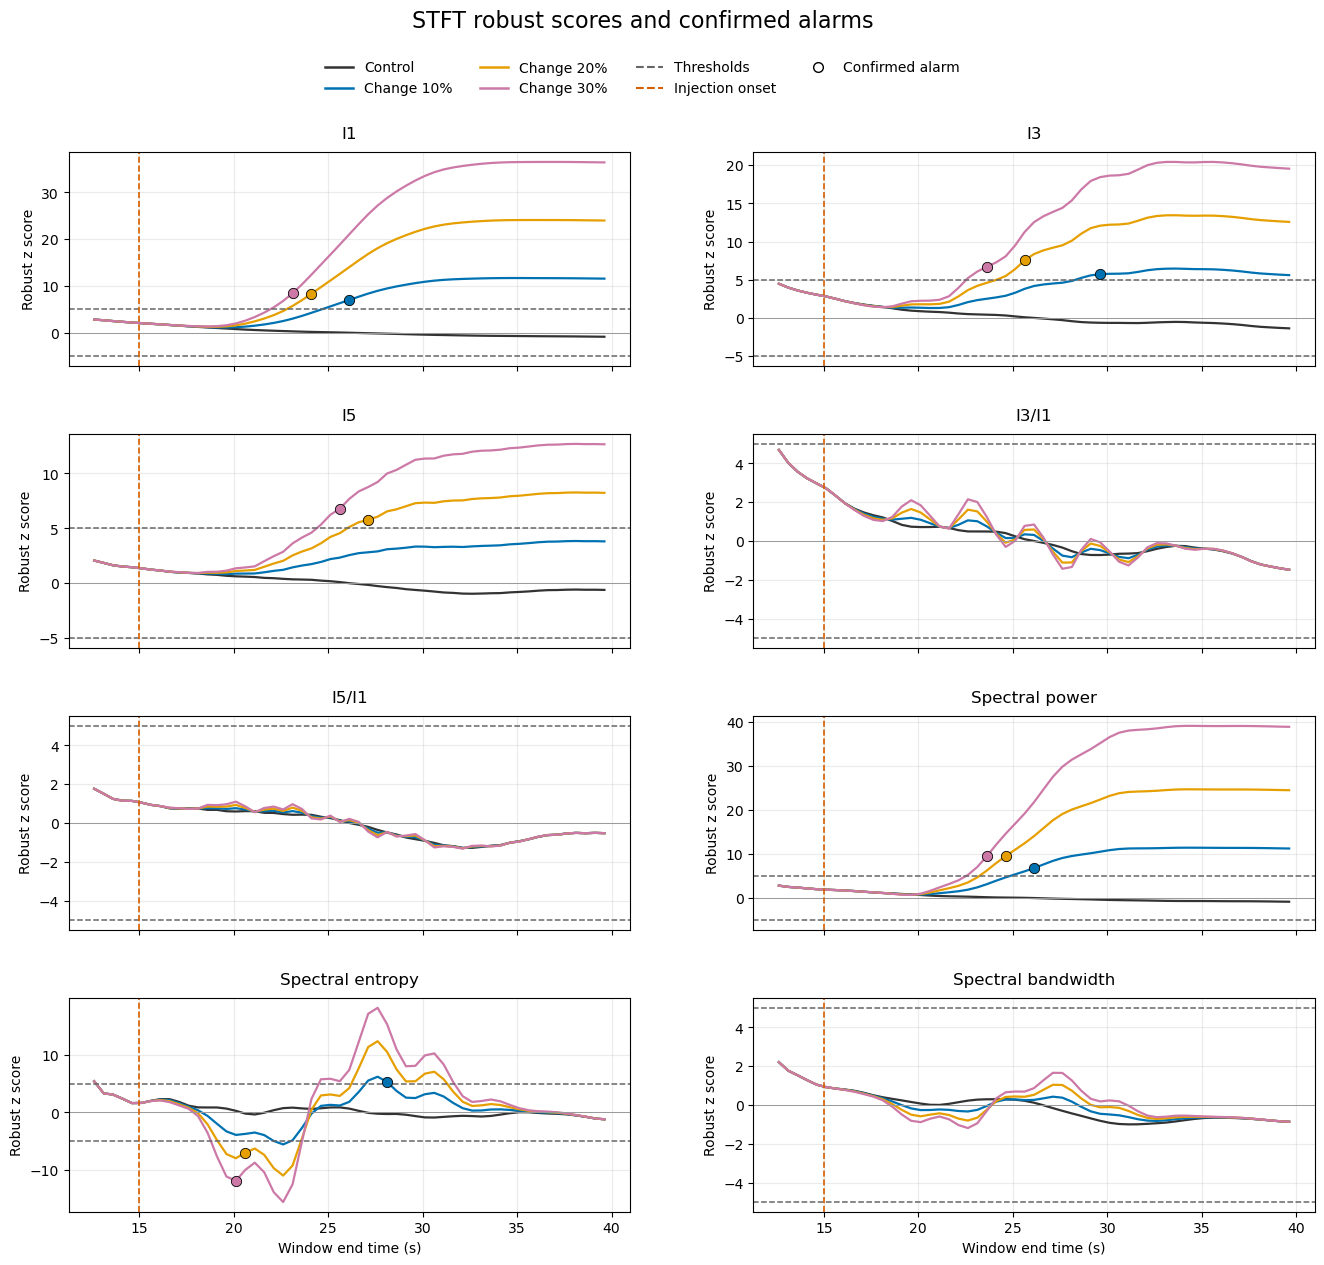

Markers show first confirmed alarms, not first threshold crossings.
The injection onset is shown for evaluation only.
Each feature uses its own control-derived scale. A larger score does not imply greater physical importance.


In [19]:
# Block 10: Visualize robust scores and confirmed alarms

from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 13),
    sharex=True,
    constrained_layout=False,
)

alarm_lookup = stft_alarm_summary.set_index(
    ["case", "feature"]
)

for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    for case, score_table in stft_score_tables.items():
        times = score_table["window_end_s"].to_numpy(dtype=float)
        scores = score_table[f"{feature}_z"].to_numpy(dtype=float)

        ax.plot(
            times,
            scores,
            color=CASE_COLORS[case],
            linewidth=1.6,
            label=CASE_LABELS[case],
        )

        alarm_row = alarm_lookup.loc[(case, feature)]

        if bool(alarm_row["confirmed"]):
            ax.scatter(
                float(alarm_row["confirmation_time_s"]),
                float(alarm_row["confirmation_z"]),
                color=CASE_COLORS[case],
                edgecolors="black",
                linewidths=0.6,
                s=55,
                zorder=5,
            )

    ax.axhline(
        Z_THRESHOLD,
        color="#666666",
        linestyle="--",
        linewidth=1.1,
    )
    ax.axhline(
        -Z_THRESHOLD,
        color="#666666",
        linestyle="--",
        linewidth=1.1,
    )
    ax.axhline(
        0,
        color="#999999",
        linewidth=0.7,
    )

    onset_values = list(ground_truth_onsets.values())

    if not np.allclose(
        onset_values, onset_values[0], rtol=0, atol=1e-9
    ):
        raise ValueError(
            "A shared onset is required for this comparison plot."
        )

    ax.axvline(
        onset_values[0],
        color="#D55E00",
        linestyle="--",
        linewidth=1.2,
    )

    ax.set_title(
        FEATURE_LABELS[feature][0],
        fontsize=12,
        pad=10,
    )
    ax.set_ylabel("Robust z score", fontsize=10)
    ax.grid(alpha=0.25)
    ax.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False,
    )

for ax in axes[-1]:
    ax.set_xlabel("Window end time (s)")

legend_handles = [
    Line2D(
        [0], [0],
        color=CASE_COLORS[case],
        linewidth=1.8,
        label=CASE_LABELS[case],
    )
    for case in stft_score_tables
]

legend_handles.extend([
    Line2D(
        [0], [0],
        color="#666666",
        linestyle="--",
        label="Thresholds",
    ),
    Line2D(
        [0], [0],
        color="#D55E00",
        linestyle="--",
        label="Injection onset",
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=7,
        label="Confirmed alarm",
    ),
])

fig.suptitle(
    "STFT robust scores and confirmed alarms",
    fontsize=16,
    y=0.985,
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=4,
    fontsize=10,
    frameon=False,
)

fig.subplots_adjust(
    top=0.875,
    bottom=0.06,
    left=0.09,
    right=0.98,
    hspace=0.32,
    wspace=0.22,
)

stft_alarm_score_figure = fig

plt.show()

print(
    "Markers show first confirmed alarms, "
    "not first threshold crossings."
)
print(
    "The injection onset is shown for evaluation only."
)
print(
    "Each feature uses its own control-derived scale. "
    "A larger score does not imply greater physical importance."
)

In [20]:
# Block 11: Evaluate threshold and persistence sensitivity

Z_THRESHOLD_GRID = [3.0, 5.0, 8.0]
PERSISTENCE_GRID_S = [0.0, 1.0, 3.0]

sensitivity_rows = []

for threshold in Z_THRESHOLD_GRID:
    for persistence_s in PERSISTENCE_GRID_S:
        for case, score_table in stft_score_tables.items():
            times_s = score_table[
                "window_end_s"
            ].to_numpy(dtype=float)

            for feature in FEATURE_COLUMNS:
                result = detect_sustained_alarm(
                    times_s=times_s,
                    z_scores=score_table[
                        f"{feature}_z"
                    ].to_numpy(dtype=float),
                    threshold=threshold,
                    persistence_s=persistence_s,
                    expected_hop_s=HOP_DURATION_S,
                )

                onset_s = ground_truth_onsets.get(case, np.nan)
                confirmation_s = result["confirmation_time_s"]
                delay_s = np.nan

                if case == "control":
                    status = (
                        "control confirmed alarm"
                        if result["confirmed"]
                        else "control no confirmed alarm"
                    )
                elif not result["confirmed"]:
                    status = "no confirmed alarm within record"
                elif confirmation_s < onset_s - 1e-9:
                    status = "pre-injection confirmed alarm"
                else:
                    status = "post-injection confirmed alarm"
                    delay_s = float(confirmation_s - onset_s)

                sensitivity_rows.append({
                    "z_threshold": threshold,
                    "persistence_s": persistence_s,
                    "case": case,
                    "feature": feature,
                    **result,
                    "ground_truth_onset_s": onset_s,
                    "evaluation_status": status,
                    "detection_delay_s": delay_s,
                })

stft_sensitivity_results = pd.DataFrame(sensitivity_rows)

configuration_rows = []
case_sensitivity_rows = []

for threshold in Z_THRESHOLD_GRID:
    for persistence_s in PERSISTENCE_GRID_S:
        config_results = stft_sensitivity_results[
            (stft_sensitivity_results["z_threshold"] == threshold)
            & (
                stft_sensitivity_results["persistence_s"]
                == persistence_s
            )
        ]

        control_results = config_results[
            config_results["case"] == "control"
        ]

        n_control_alarms = int(
            control_results["confirmed"].sum()
        )

        n_pre_injection = int(
            (
                config_results["evaluation_status"]
                == "pre-injection confirmed alarm"
            ).sum()
        )

        configuration_row = {
            "z_threshold": threshold,
            "persistence_s": persistence_s,
            "is_primary_configuration": (
                threshold == Z_THRESHOLD
                and persistence_s == PERSISTENCE_S
            ),
            "n_control_confirmed_features": n_control_alarms,
            "n_pre_injection_confirmed_case_feature_pairs": (
                n_pre_injection
            ),
        }

        for case in ground_truth_onsets:
            case_results = config_results[
                config_results["case"] == case
            ]

            pre_results = case_results[
                case_results["evaluation_status"]
                == "pre-injection confirmed alarm"
            ]

            post_results = case_results[
                case_results["evaluation_status"]
                == "post-injection confirmed alarm"
            ]

            if post_results.empty:
                earliest_time = np.nan
                earliest_delay = np.nan
                earliest_features = "none"
            else:
                earliest_time = float(
                    post_results["confirmation_time_s"].min()
                )
                earliest_delay = (
                    earliest_time - ground_truth_onsets[case]
                )

                tied_results = post_results[
                    np.isclose(
                        post_results["confirmation_time_s"],
                        earliest_time,
                        rtol=0,
                        atol=1e-9,
                    )
                ]

                earliest_features = ", ".join(
                    FEATURE_LABELS[feature][0]
                    for feature in tied_results["feature"]
                )

            case_sensitivity_rows.append({
                "z_threshold": threshold,
                "persistence_s": persistence_s,
                "case": case,
                "n_pre_injection_confirmed_features": len(
                    pre_results
                ),
                "n_post_injection_confirmed_features": len(
                    post_results
                ),
                "earliest_post_injection_confirmation_s": (
                    earliest_time
                ),
                "earliest_post_injection_delay_s": earliest_delay,
                "earliest_features": earliest_features,
            })

            configuration_row[
                f"{case}_earliest_post_delay_s"
            ] = earliest_delay

        configuration_rows.append(configuration_row)

stft_sensitivity_config_summary = pd.DataFrame(
    configuration_rows
)

stft_sensitivity_case_summary = pd.DataFrame(
    case_sensitivity_rows
)

print("Configuration-level sensitivity summary:")
display(stft_sensitivity_config_summary)

print("\nCase-level sensitivity summary:")
display(stft_sensitivity_case_summary)

primary_sensitivity = (
    stft_sensitivity_results[
        (stft_sensitivity_results["z_threshold"] == Z_THRESHOLD)
        & (
            stft_sensitivity_results["persistence_s"]
            == PERSISTENCE_S
        )
    ]
    .set_index(["case", "feature"])
    .sort_index()
)

primary_original = (
    stft_alarm_summary
    .set_index(["case", "feature"])
    .sort_index()
)

assert primary_sensitivity.index.equals(primary_original.index)

assert np.allclose(
    primary_sensitivity["confirmation_time_s"].to_numpy(),
    primary_original["confirmation_time_s"].to_numpy(),
    rtol=0,
    atol=1e-9,
    equal_nan=True,
)

print("\nPrimary configuration reproduced successfully.")
print(
    "Control alarms are calibration-record diagnostics, "
    "not an independently validated false-alarm rate."
)
print(
    "Post-injection delay summaries must be interpreted "
    "alongside pre-injection alarm counts."
)
print(
    "Only the first confirmed alarm per feature is evaluated. "
    "A pre-injection first alarm is not replaced by a later alarm."
)
print(
    "This analysis describes parameter sensitivity "
    "and does not establish a universally optimal configuration."
)

Configuration-level sensitivity summary:


,z_threshold,persistence_s,is_primary_configuration,n_control_confirmed_features,n_pre_injection_confirmed_case_feature_pairs,change_10pct_earliest_post_delay_s,change_20pct_earliest_post_delay_s,change_30pct_earliest_post_delay_s
0,3.0,0.0,False,3,9,8.12,6.62,6.12
1,3.0,1.0,False,3,9,9.12,7.62,7.12
2,3.0,3.0,False,0,0,7.62,7.12,6.62
3,5.0,0.0,False,1,3,10.12,8.12,7.12
4,5.0,1.0,True,0,0,11.12,5.62,5.12
5,5.0,3.0,False,0,0,13.12,7.62,7.12
6,8.0,0.0,False,0,0,12.12,5.12,4.62
7,8.0,1.0,False,0,0,13.12,8.12,5.62
8,8.0,3.0,False,0,0,15.12,12.12,7.62



Case-level sensitivity summary:


,z_threshold,persistence_s,case,n_pre_injection_confirmed_features,n_post_injection_confirmed_features,earliest_post_injection_confirmation_s,earliest_post_injection_delay_s,earliest_features
0,3.0,0.0,change_10pct,3,3,23.12,8.12,I1
1,3.0,0.0,change_20pct,3,3,21.62,6.62,I1
2,3.0,0.0,change_30pct,3,3,21.12,6.12,I1
3,3.0,1.0,change_10pct,3,3,24.12,9.12,I1
4,3.0,1.0,change_20pct,3,3,22.62,7.62,I1
5,3.0,1.0,change_30pct,3,3,22.12,7.12,I1
6,3.0,3.0,change_10pct,0,5,22.62,7.62,Spectral entropy
7,3.0,3.0,change_20pct,0,5,22.12,7.12,Spectral entropy
8,3.0,3.0,change_30pct,0,5,21.62,6.62,Spectral entropy
9,5.0,0.0,change_10pct,1,3,25.12,10.12,"I1, Spectral power"



Primary configuration reproduced successfully.
Control alarms are calibration-record diagnostics, not an independently validated false-alarm rate.
Post-injection delay summaries must be interpreted alongside pre-injection alarm counts.
Only the first confirmed alarm per feature is evaluated. A pre-injection first alarm is not replaced by a later alarm.
This analysis describes parameter sensitivity and does not establish a universally optimal configuration.


In [13]:
# Block 12: Check harmonic estimation across shorter windows

WINDOW_CYCLE_CANDIDATES = [2.0, 1.0, 0.5]
CALIBRATION_PHASES = np.linspace(
    0.0, 2.0 * np.pi, 24, endpoint=False
)

known_feature_values = {
    "I1_Pa": 0.2,
    "I3_Pa": 0.02,
    "I5_Pa": 0.007,
    "I3_I1": 0.1,
    "I5_I1": 0.035,
}

short_window_calibration_rows = []
short_window_setting_rows = []

for requested_cycles in WINDOW_CYCLE_CANDIDATES:
    n_samples = int(round(
        requested_cycles * PERIOD_S * SAMPLING_HZ
    ))

    duration_s = n_samples / SAMPLING_HZ
    actual_cycles = duration_s / PERIOD_S
    local_times_s = np.arange(n_samples) / SAMPLING_HZ

    frequencies_hz = np.fft.rfftfreq(
        n_samples, d=1.0 / SAMPLING_HZ
    )

    band_mask = (
        (frequencies_hz >= SPECTRAL_BAND_HZ[0])
        & (frequencies_hz <= SPECTRAL_BAND_HZ[1])
    )

    short_window_setting_rows.append({
        "requested_cycles": requested_cycles,
        "actual_cycles": actual_cycles,
        "n_samples": n_samples,
        "window_duration_s": duration_s,
        "frequency_bin_spacing_Hz": SAMPLING_HZ / n_samples,
        "n_spectral_band_bins": int(band_mask.sum()),
    })

    for phase_index, phase in enumerate(CALIBRATION_PHASES):
        base_phase = OMEGA_RAD_S * local_times_s + phase

        test_signal = (
            0.05
            + 0.2 * np.sin(base_phase + 0.3)
            + 0.02 * np.sin(3.0 * base_phase - 0.4)
            + 0.007 * np.sin(5.0 * base_phase + 0.8)
        )

        estimated_features = extract_window_features(
            signal_values=test_signal,
            sampling_hz=SAMPLING_HZ,
            fundamental_hz=FUNDAMENTAL_HZ,
            spectral_band_hz=SPECTRAL_BAND_HZ,
        )

        if estimated_features["parseval_relative_error"] > 1e-10:
            raise ValueError(
                "Parseval consistency check failed."
            )

        for feature, known_value in known_feature_values.items():
            estimate = float(estimated_features[feature])

            if not np.isfinite(estimate):
                raise ValueError(
                    f"Invalid calibration estimate: {feature}"
                )

            signed_error_percent = (
                100.0 * (estimate - known_value) / known_value
            )

            short_window_calibration_rows.append({
                "requested_cycles": requested_cycles,
                "window_duration_s": duration_s,
                "phase_index": phase_index,
                "phase_rad": float(phase),
                "feature": feature,
                "known_value": known_value,
                "estimated_value": estimate,
                "signed_error_percent": signed_error_percent,
                "absolute_error_percent": abs(
                    signed_error_percent
                ),
            })

short_window_settings = pd.DataFrame(
    short_window_setting_rows
)

short_window_calibration_results = pd.DataFrame(
    short_window_calibration_rows
)

short_window_calibration_summary = (
    short_window_calibration_results
    .groupby(
        ["requested_cycles", "window_duration_s", "feature"],
        sort=False,
    )
    .agg(
        median_absolute_error_percent=(
            "absolute_error_percent", "median"
        ),
        max_absolute_error_percent=(
            "absolute_error_percent", "max"
        ),
        min_estimated_value=("estimated_value", "min"),
        max_estimated_value=("estimated_value", "max"),
    )
    .reset_index()
)

print("Candidate window settings:")
display(short_window_settings)

print("\nHarmonic estimation errors across 24 starting phases:")
display(short_window_calibration_summary)

print(
    "\nThis calibration uses known stationary harmonic amplitudes."
)
print(
    "Shorter windows may introduce phase-dependent estimation bias."
)
print(
    "Parseval consistency verifies power normalization; "
    "it does not establish accurate harmonic separation."
)
print(
    "Spectral entropy and bandwidth use different frequency grids "
    "at different window lengths."
)
print(
    "Primary feature tables and alarm results remain unchanged."
)

Candidate window settings:


,requested_cycles,actual_cycles,n_samples,window_duration_s,frequency_bin_spacing_Hz,n_spectral_band_bins
0,2.0,1.998986,628,12.56,0.079618,15
1,1.0,0.999493,314,6.28,0.159236,7
2,0.5,0.499747,157,3.14,0.318471,3



Harmonic estimation errors across 24 starting phases:


,requested_cycles,window_duration_s,feature,median_absolute_error_percent,max_absolute_error_percent,min_estimated_value,max_estimated_value
0,2.0,12.56,I1_Pa,0.002343,0.003283,0.199993,0.200007
1,2.0,12.56,I3_Pa,0.022999,0.037599,0.019992,0.020007
2,2.0,12.56,I5_Pa,0.018126,0.038705,0.006997,0.007001
3,2.0,12.56,I3_I1,0.023699,0.038702,0.099961,0.100034
4,2.0,12.56,I5_I1,0.017881,0.040876,0.034986,0.035008
5,1.0,6.28,I1_Pa,0.025208,0.034142,0.199932,0.199968
6,1.0,6.28,I3_Pa,0.117491,0.184407,0.019963,0.020034
7,1.0,6.28,I5_Pa,0.076067,0.168632,0.006988,0.007006
8,1.0,6.28,I3_I1,0.116188,0.197727,0.099842,0.100198
9,1.0,6.28,I5_I1,0.075977,0.137395,0.034952,0.035041



This calibration uses known stationary harmonic amplitudes.
Shorter windows may introduce phase-dependent estimation bias.
Parseval consistency verifies power normalization; it does not establish accurate harmonic separation.
Spectral entropy and bandwidth use different frequency grids at different window lengths.
Primary feature tables and alarm results remain unchanged.


In [21]:
# Block 13: Compare one-cycle and two-cycle alarm results

COMPARISON_WINDOW_CYCLES = [2.0, 1.0]

window_comparison_feature_tables = {}
window_comparison_reference_tables = {}
window_comparison_score_tables = {}

window_alarm_rows = []

for cycles in COMPARISON_WINDOW_CYCLES:
    n_window = int(round(
        cycles * PERIOD_S * SAMPLING_HZ
    ))
    duration_s = n_window / SAMPLING_HZ

    feature_tables = {}

    for case, record in laos_prepared_records.items():
        data = record["data"]
        times = data["time_s"].to_numpy(dtype=float)
        stress = data["stress_Pa"].to_numpy(dtype=float)

        rows = []

        for start in range(
            0, len(times) - n_window + 1, N_HOP
        ):
            stop = start + n_window

            features = extract_window_features(
                signal_values=stress[start:stop],
                sampling_hz=SAMPLING_HZ,
                fundamental_hz=FUNDAMENTAL_HZ,
                spectral_band_hz=SPECTRAL_BAND_HZ,
            )

            if not all(
                np.isfinite(features[feature])
                for feature in FEATURE_COLUMNS
            ):
                raise ValueError(
                    f"Invalid features: cycles={cycles}, case={case}"
                )

            if features["parseval_relative_error"] > 1e-10:
                raise ValueError("Parseval check failed.")

            start_s = float(times[start])

            rows.append({
                "window_start_s": start_s,
                "window_center_s": start_s + duration_s / 2.0,
                "window_end_s": start_s + duration_s,
                **features,
            })

        feature_tables[case] = pd.DataFrame(rows)

    reference = feature_tables["control"][FEATURE_COLUMNS]

    reference_medians = reference.median()
    reference_mads = (
        reference - reference_medians
    ).abs().median()
    reference_scales = 1.4826 * reference_mads

    if (
        not np.all(np.isfinite(reference_scales))
        or np.any(reference_scales <= 0)
    ):
        raise ValueError(
            f"Invalid control reference scales: cycles={cycles}"
        )

    reference_summary = pd.DataFrame({
        "reference_median": reference_medians,
        "reference_MAD": reference_mads,
        "reference_scale": reference_scales,
    })

    score_tables = {}

    for case, feature_table in feature_tables.items():
        score_table = feature_table[time_columns].copy()

        for feature in FEATURE_COLUMNS:
            scores = (
                feature_table[feature].to_numpy(dtype=float)
                - reference_medians[feature]
            ) / reference_scales[feature]

            score_table[f"{feature}_z"] = scores

            result = detect_sustained_alarm(
                times_s=feature_table[
                    "window_end_s"
                ].to_numpy(dtype=float),
                z_scores=scores,
                threshold=Z_THRESHOLD,
                persistence_s=PERSISTENCE_S,
                expected_hop_s=HOP_DURATION_S,
            )

            onset_s = ground_truth_onsets.get(case, np.nan)
            confirmation_s = result["confirmation_time_s"]
            delay_s = np.nan

            if case == "control":
                status = (
                    "control confirmed alarm"
                    if result["confirmed"]
                    else "control no confirmed alarm"
                )
            elif not result["confirmed"]:
                status = "no confirmed alarm within record"
            elif confirmation_s < onset_s - 1e-9:
                status = "pre-injection confirmed alarm"
            else:
                status = "post-injection confirmed alarm"
                delay_s = float(confirmation_s - onset_s)

            window_alarm_rows.append({
                "requested_cycles": cycles,
                "window_duration_s": duration_s,
                "case": case,
                "feature": feature,
                "n_feature_windows": len(feature_table),
                "first_available_window_end_s": float(
                    feature_table["window_end_s"].iloc[0]
                ),
                **result,
                "evaluation_status": status,
                "detection_delay_s": delay_s,
            })

        score_tables[case] = score_table

    window_comparison_feature_tables[cycles] = feature_tables
    window_comparison_reference_tables[cycles] = reference_summary
    window_comparison_score_tables[cycles] = score_tables

window_comparison_alarm_results = pd.DataFrame(window_alarm_rows)

two_cycle_results = (
    window_comparison_alarm_results[
        window_comparison_alarm_results["requested_cycles"] == 2.0
    ]
    .set_index(["case", "feature"])
    .sort_index()
)

original_results = (
    stft_alarm_summary
    .set_index(["case", "feature"])
    .sort_index()
)

assert two_cycle_results.index.equals(original_results.index)

assert np.allclose(
    two_cycle_results["confirmation_time_s"].to_numpy(),
    original_results["confirmation_time_s"].to_numpy(),
    rtol=0,
    atol=1e-9,
    equal_nan=True,
)

print("Two-cycle primary alarm results reproduced successfully.")

for cycles in COMPARISON_WINDOW_CYCLES:
    selected = window_comparison_alarm_results[
        window_comparison_alarm_results["requested_cycles"] == cycles
    ]

    delay_table = (
        selected[selected["case"].isin(ground_truth_onsets)]
        .pivot(
            index="feature",
            columns="case",
            values="detection_delay_s",
        )
        .reindex(
            index=FEATURE_COLUMNS,
            columns=list(ground_truth_onsets),
        )
    )

    delay_table.index = [
        FEATURE_LABELS[feature][0]
        for feature in delay_table.index
    ]
    delay_table.columns = [
        CASE_LABELS[case]
        for case in delay_table.columns
    ]

    print(f"\nWindow: {cycles:g} cycle(s)")
    print("Post-injection confirmation delays (s):")
    display(delay_table)

    print("Control and pre-injection alarm diagnostics:")
    display(
        selected[
            (selected["case"] == "control")
            | (
                selected["evaluation_status"]
                == "pre-injection confirmed alarm"
            )
        ][
            [
                "case",
                "feature",
                "first_available_window_end_s",
                "confirmation_time_s",
                "evaluation_status",
            ]
        ]
    )

print(
    "\nEach window length uses its own full-control reference."
)
print(
    "Shorter windows become available earlier and provide "
    "a longer pre-injection monitoring interval."
)
print(
    "Entropy and bandwidth use different frequency grids "
    "across window lengths."
)
print(
    "Half-cycle harmonic estimates are excluded from this "
    "primary comparison because of large calibration errors."
)

Two-cycle primary alarm results reproduced successfully.

Window: 2 cycle(s)
Post-injection confirmation delays (s):


,Change 10%,Change 20%,Change 30%
I1,11.12,9.12,8.12
I3,14.62,10.62,8.62
I5,NaN,12.12,10.62
I3/I1,NaN,NaN,NaN
I5/I1,NaN,NaN,NaN
Spectral power,11.12,9.62,8.62
Spectral entropy,13.12,5.62,5.12
Spectral bandwidth,NaN,NaN,NaN


Control and pre-injection alarm diagnostics:


,case,feature,first_available_window_end_s,confirmation_time_s,evaluation_status
0,control,I1_Pa,12.62,NaN,control no confirmed alarm
1,control,I3_Pa,12.62,NaN,control no confirmed alarm
2,control,I5_Pa,12.62,NaN,control no confirmed alarm
3,control,I3_I1,12.62,NaN,control no confirmed alarm
4,control,I5_I1,12.62,NaN,control no confirmed alarm
5,control,spectral_power_Pa2,12.62,NaN,control no confirmed alarm
6,control,spectral_entropy,12.62,NaN,control no confirmed alarm
7,control,spectral_bandwidth_Hz,12.62,NaN,control no confirmed alarm



Window: 1 cycle(s)
Post-injection confirmation delays (s):


,Change 10%,Change 20%,Change 30%
I1,8.34,6.34,5.34
I3,16.84,8.34,8.34
I5,NaN,10.84,8.84
I3/I1,NaN,NaN,NaN
I5/I1,NaN,NaN,NaN
Spectral power,12.34,8.84,7.84
Spectral entropy,NaN,NaN,NaN
Spectral bandwidth,NaN,NaN,NaN


Control and pre-injection alarm diagnostics:


,case,feature,first_available_window_end_s,confirmation_time_s,evaluation_status
32,control,I1_Pa,6.34,NaN,control no confirmed alarm
33,control,I3_Pa,6.34,NaN,control no confirmed alarm
34,control,I5_Pa,6.34,NaN,control no confirmed alarm
35,control,I3_I1,6.34,NaN,control no confirmed alarm
36,control,I5_I1,6.34,NaN,control no confirmed alarm
37,control,spectral_power_Pa2,6.34,NaN,control no confirmed alarm
38,control,spectral_entropy,6.34,NaN,control no confirmed alarm
39,control,spectral_bandwidth_Hz,6.34,NaN,control no confirmed alarm



Each window length uses its own full-control reference.
Shorter windows become available earlier and provide a longer pre-injection monitoring interval.
Entropy and bandwidth use different frequency grids across window lengths.
Half-cycle harmonic estimates are excluded from this primary comparison because of large calibration errors.


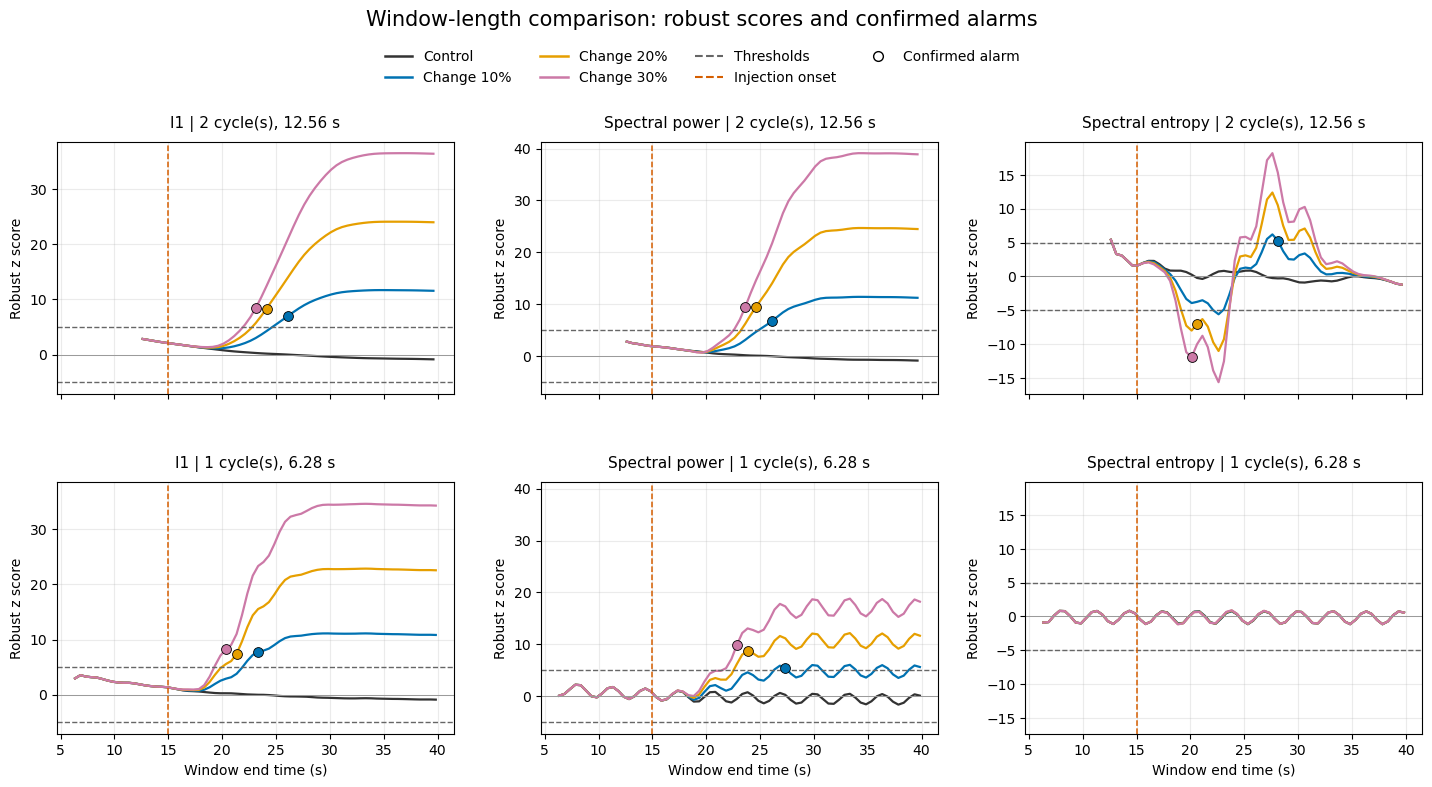

Columns share vertical limits across window lengths.
Each window length uses its own control-derived location and scale.
Missing markers mean no confirmed alarm within the available record.


In [22]:
# Block 14: Inspect score changes across window lengths

COMPARISON_FEATURES = [
    "I1_Pa",
    "spectral_power_Pa2",
    "spectral_entropy",
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharex=True,
    sharey="col",
    constrained_layout=False,
)

for row_index, cycles in enumerate(COMPARISON_WINDOW_CYCLES):
    duration_s = (
        round(cycles * PERIOD_S * SAMPLING_HZ)
        / SAMPLING_HZ
    )

    score_tables = window_comparison_score_tables[cycles]

    for column_index, feature in enumerate(COMPARISON_FEATURES):
        ax = axes[row_index, column_index]

        for case, score_table in score_tables.items():
            ax.plot(
                score_table["window_end_s"],
                score_table[f"{feature}_z"],
                color=CASE_COLORS[case],
                linewidth=1.6,
            )

            alarm_rows = window_comparison_alarm_results[
                (
                    window_comparison_alarm_results[
                        "requested_cycles"
                    ] == cycles
                )
                & (
                    window_comparison_alarm_results["case"]
                    == case
                )
                & (
                    window_comparison_alarm_results["feature"]
                    == feature
                )
            ]

            alarm_row = alarm_rows.iloc[0]

            if bool(alarm_row["confirmed"]):
                ax.scatter(
                    alarm_row["confirmation_time_s"],
                    alarm_row["confirmation_z"],
                    color=CASE_COLORS[case],
                    edgecolors="black",
                    linewidths=0.6,
                    s=50,
                    zorder=5,
                )

        for threshold in [Z_THRESHOLD, -Z_THRESHOLD]:
            ax.axhline(
                threshold,
                color="#666666",
                linestyle="--",
                linewidth=1.0,
            )

        ax.axhline(0, color="#999999", linewidth=0.7)

        for onset_s in sorted(set(ground_truth_onsets.values())):
            ax.axvline(
                onset_s,
                color="#D55E00",
                linestyle="--",
                linewidth=1.1,
            )

        ax.set_title(
            f"{FEATURE_LABELS[feature][0]} | "
            f"{cycles:g} cycle(s), {duration_s:.2f} s",
            fontsize=11,
            pad=10,
        )
        ax.set_ylabel("Robust z score")
        ax.grid(alpha=0.25)

for ax in axes[-1]:
    ax.set_xlabel("Window end time (s)")

fig.suptitle(
    "Window-length comparison: robust scores and confirmed alarms",
    fontsize=15,
    y=0.985,
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=4,
    fontsize=10,
    frameon=False,
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.08,
    left=0.07,
    right=0.98,
    hspace=0.35,
    wspace=0.22,
)

stft_window_comparison_figure = fig

plt.show()

print(
    "Columns share vertical limits across window lengths."
)
print(
    "Each window length uses its own control-derived "
    "location and scale."
)
print(
    "Missing markers mean no confirmed alarm "
    "within the available record."
)

In [24]:
# Block 15: Export the semi-synthetic STFT analysis

from datetime import datetime
import hashlib

run_stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
STFT_OUTPUT_DIR = (
    DATA_DIR / "results" / f"STFT_semisynthetic_{run_stamp}"
)
STFT_OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

export_tables = {
    "data_summary": stft_data_summary,
    "window_schedule": window_schedule,
    "feature_checks": stft_feature_checks,
    "features_primary": stft_feature_long_table,
    "paired_feature_responses": stft_response_summary,
    "reference_primary": stft_reference_summary.reset_index(),
    "control_score_diagnostics": control_score_summary,
    "alarms_primary": stft_alarm_summary,
    "alarm_evaluation_primary": stft_alarm_evaluation,
    "case_detection_summary": stft_case_detection_summary,
    "sensitivity_per_feature": stft_sensitivity_results,
    "sensitivity_config_summary": stft_sensitivity_config_summary,
    "sensitivity_case_summary": stft_sensitivity_case_summary,
    "short_window_settings": short_window_settings,
    "short_window_calibration": short_window_calibration_results,
    "short_window_calibration_summary": (
        short_window_calibration_summary
    ),
    "window_comparison_alarms": window_comparison_alarm_results,
}

for cycles, case_tables in window_comparison_feature_tables.items():
    cycle_tag = f"{cycles:g}".replace(".", "p")

    export_tables[f"features_{cycle_tag}_cycle"] = pd.concat(
        [
            table.assign(case=case)
            for case, table in case_tables.items()
        ],
        ignore_index=True,
    )

    export_tables[f"scores_{cycle_tag}_cycle"] = pd.concat(
        [
            table.assign(case=case)
            for case, table in
            window_comparison_score_tables[cycles].items()
        ],
        ignore_index=True,
    )

    export_tables[f"reference_{cycle_tag}_cycle"] = (
        window_comparison_reference_tables[cycles]
        .rename_axis("feature")
        .reset_index()
    )

for name, table in export_tables.items():
    table.to_csv(
        STFT_OUTPUT_DIR / f"{name}.csv",
        index=False,
    )

export_figures = {
    "feature_trajectories": stft_feature_figure,
    "paired_feature_responses": stft_paired_feature_figure,
    "alarm_scores": stft_alarm_score_figure,
    "window_comparison": stft_window_comparison_figure,
}

for name, figure in export_figures.items():
    figure.savefig(
        STFT_OUTPUT_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    figure.savefig(
        STFT_OUTPUT_DIR / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )

source_paths = (
    list(OBSERVED_DIR.glob("*.csv"))
    + list(TRUTH_DIR.glob("*.csv"))
    + [METADATA_PATH]
)

source_hashes = {
    str(path.relative_to(DATA_DIR)): hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in sorted(set(source_paths))
    if path.is_file()
}

export_config = {
    "created_at_local": datetime.now().isoformat(),
    "benchmark_metadata": benchmark_metadata,
    "primary_stft_settings": stft_settings,
    "primary_alarm_config": stft_alarm_config,
    "features": FEATURE_COLUMNS,
    "ground_truth_onsets_s": ground_truth_onsets,
    "sensitivity_z_thresholds": Z_THRESHOLD_GRID,
    "sensitivity_persistence_s": PERSISTENCE_GRID_S,
    "calibration_window_cycles": WINDOW_CYCLE_CANDIDATES,
    "comparison_window_cycles": COMPARISON_WINDOW_CYCLES,
    "calibration_starting_phases_rad": (
        CALIBRATION_PHASES.tolist()
    ),
    "source_sha256": source_hashes,
}

def json_converter(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Unsupported JSON type: {type(value)}")

(STFT_OUTPUT_DIR / "analysis_config.json").write_text(
    json.dumps(
        export_config,
        indent=2,
        default=json_converter,
        allow_nan=False,
    ),
    encoding="utf-8",
)

analysis_notes = """Semi-synthetic LAOS STFT analysis

Scope
- Candidate detection of specified stress-gain injections.
- Results do not establish physiological clotting times.
- Cases share one measured APR18 background.

Feature interpretation
- Harmonic amplitudes describe absolute response magnitude.
- Harmonic ratios describe relative harmonic contributions.
- Spectral power is integrated over the specified frequency band.
- Entropy and bandwidth describe the selected spectral distribution.
- Uniform stress scaling does not inherently increase relative
  harmonic distortion.
- Transition-window spectral changes can arise from time-varying gain.

Alarm evaluation
- Reference statistics use the full matched control record.
- This is offline calibration, not prospective online validation.
- Control diagnostics reuse the calibration record.
- Scores use the median and 1.4826 times MAD.
- Confirmation requires consecutive same-direction exceedances
  with absolute signed z scores at or above the threshold.
- Nonfinite scores, direction changes, below-threshold outputs,
  and time gaps interrupt a run.
- Overlapping outputs are not independent confirmations.
- Alarm timestamps are exclusive window ends.
- Detection delay uses confirmation time, not retrospective run start.
- Ground truth is used only to evaluate frozen alarm results.
- Only the first confirmed alarm per feature is evaluated.
- Earliest times across features are descriptive summaries.

Sensitivity and window comparison
- Threshold and persistence affect both delay and background alarms.
- Post-injection delays must be read with pre-injection alarm counts.
- Each window length uses its own full-control reference.
- Shorter windows provide earlier feature availability.
- Entropy and bandwidth use different frequency grids across windows.
- Half-cycle harmonic estimates show large calibration errors under
  the current estimator and are excluded from the main comparison.
- Calibration errors describe the tested stationary signal and phases,
  not all possible signals.
- The tested one-cycle window remains longer than five seconds.
- No universally optimal threshold, feature or window is established.
"""

(STFT_OUTPUT_DIR / "analysis_notes.txt").write_text(
    analysis_notes,
    encoding="utf-8",
)

output_files = sorted(
    path for path in STFT_OUTPUT_DIR.iterdir()
    if path.is_file()
)

if any(path.stat().st_size == 0 for path in output_files):
    raise RuntimeError("An exported file is empty.")

export_manifest = {
    path.name: hashlib.sha256(path.read_bytes()).hexdigest()
    for path in output_files
}

(STFT_OUTPUT_DIR / "export_SHA256.json").write_text(
    json.dumps(export_manifest, indent=2),
    encoding="utf-8",
)

print("STFT export completed.")
print(f"Output directory: {STFT_OUTPUT_DIR.resolve()}")
print(f"CSV tables: {len(export_tables)}")
print(f"Figures: {len(export_figures)} PNG + PDF pairs")
print("Configuration, interpretation notes and hashes saved.")

STFT export completed.
Output directory: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/results/STFT_semisynthetic_20261011_022909_071695
CSV tables: 23
Figures: 4 PNG + PDF pairs
Configuration, interpretation notes and hashes saved.
